In [58]:
import sys
import pandas as pd

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)

Python executable: d:\DAC\CHURN_PREDICTION\.venv\Scripts\python.exe
Python version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.1.1


# Churn Prediction – Exploratory Data Analysis

## 1. Project Overview

This notebook explores merchant-level financial GMV, and Search Traffic features to understand patterns associated with next-month churn.

**Dataset:** `data/processed/training_set.csv`

**Observation grain:** One merchant × one monthly snapshot.

**Target:** `churn_next_30d`

**Data split:**
- Train: June–July 2026
- Test: August 2026

## 2. EDA Objectives

1. Analyze churn by merchant tenure and MRR.
2. Investigate churn differences by GMV and Search data availability.
3. Compare GMV and Search activity between churned and non-churned merchants.
4. Identify skewed features and potential outliers.
5. Investigate the relationship between missing values and churn.
6. Assess churn stability between June and July 2026.

## A. Data Preparation

In [59]:
# 1. Import libraries
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Set project path
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "training_set.csv"

# 3. Load dataset
df = pd.read_csv(DATA_PATH)

# 4. Convert snapshot_month to datetime
df["snapshot_month"] = pd.to_datetime(df["snapshot_month"])

# 5. Basic information
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Python executable:", sys.executable)
print("Dataset shape:", df.shape)
print("\nSnapshot months:")
print(df["snapshot_month"].value_counts().sort_index())
print("\nData split:")
print(df["split"].value_counts())
print("\nTarget distribution:")
print(df["churn_next_30d"].value_counts())

Project root: d:\DAC\CHURN_PREDICTION
Dataset path: d:\DAC\CHURN_PREDICTION\data\processed\training_set.csv
Python executable: d:\DAC\CHURN_PREDICTION\.venv\Scripts\python.exe
Dataset shape: (25556, 46)

Snapshot months:
snapshot_month
2026-06-01    8669
2026-07-01    8512
2026-08-01    8375
Name: count, dtype: int64

Data split:
split
train    17181
test      8375
Name: count, dtype: int64

Target distribution:
churn_next_30d
0    24889
1      667
Name: count, dtype: int64


## B. EDA

### 1. Churn by Merchant Tenure and MRR (dataset)

In [60]:
# Create a working copy for EDA
eda_df = df.copy()

# 1. Group merchants by tenure
tenure_bins = [-np.inf, 3, 6, 12, 24, 36, np.inf]
tenure_labels = [
    "0-3 months",
    "4-6 months",
    "7-12 months",
    "13-24 months",
    "25-36 months",
    "Over 36 months"
]
eda_df["tenure_group"] = pd.cut(
    eda_df["tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# 2. Group merchants by EOM MRR quartiles
eda_df["mrr_group"] = pd.qcut(
    eda_df["eom_mrr"],
    q=4,
    duplicates="drop"
)

# 3. Calculate churn statistics
def calculate_churn_rate(data, group_column):
    result = (
        data.groupby(group_column, observed=True)
        .agg(
            merchant_months=("churn_next_30d", "size"),
            churn_count=("churn_next_30d", "sum"),
            churn_rate=("churn_next_30d", "mean")
        )
        .reset_index()
    )

    result["churn_rate_pct"] = result["churn_rate"] * 100

    return result.drop(columns="churn_rate")

# 4. Churn by tenure
tenure_churn = calculate_churn_rate(
    eda_df, "tenure_group"
)
print("CHURN RATE BY TENURE")
display(tenure_churn)

# 5. Churn by MRR
mrr_churn = calculate_churn_rate(
    eda_df, "mrr_group"
)
print("\nCHURN RATE BY MRR")
display(mrr_churn)

CHURN RATE BY TENURE


,tenure_group,merchant_months,churn_count,churn_rate_pct
0,0-3 months,892,82,9.192825
1,4-6 months,520,24,4.615385
2,7-12 months,1078,39,3.617811
3,13-24 months,1847,53,2.869518
4,25-36 months,3052,77,2.522936
5,Over 36 months,18167,392,2.157759



CHURN RATE BY MRR


,mrr_group,merchant_months,churn_count,churn_rate_pct
0,"(0.099, 19.0]",8681,178,2.050455
1,"(19.0, 29.0]",5158,181,3.509112
2,"(29.0, 79.0]",5836,141,2.416038
3,"(79.0, 5500.0]",5881,167,2.839653


### Churn by Merchant Tenure and MRR (training set)

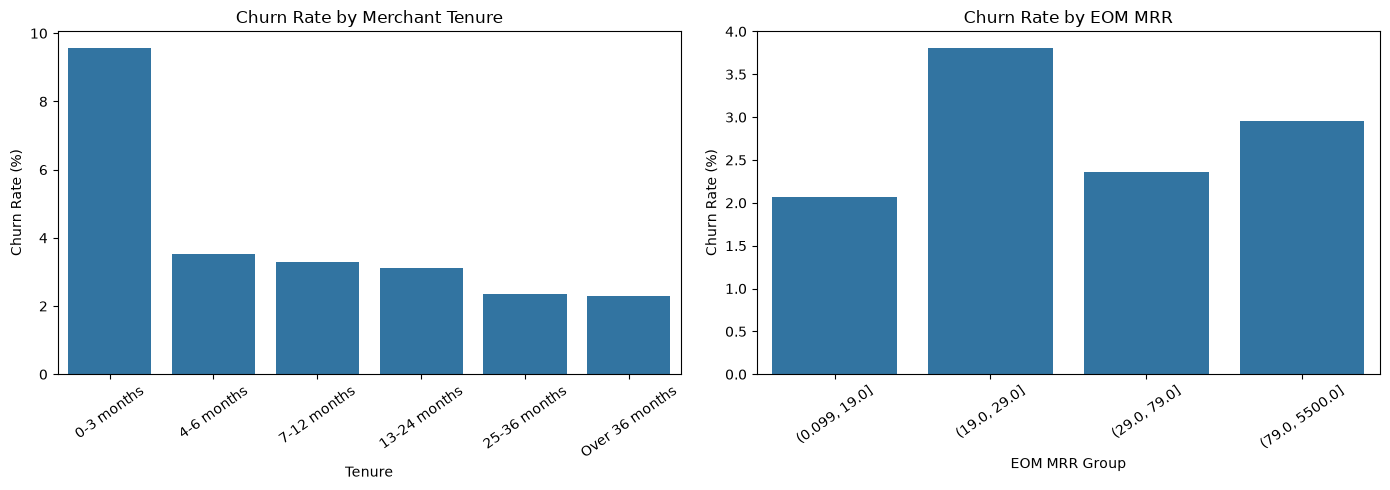

,tenure_group,merchant_months,churn_count,churn_rate_pct
0,0-3 months,616,59,9.577922
1,4-6 months,339,12,3.539823
2,7-12 months,730,24,3.287671
3,13-24 months,1250,39,3.120000
4,25-36 months,2079,49,2.356902
5,Over 36 months,12167,279,2.293088


,mrr_group,merchant_months,churn_count,churn_rate_pct
0,"(0.099, 19.0]",5847,121,2.069437
1,"(19.0, 29.0]",3464,132,3.810624
2,"(29.0, 79.0]",3945,93,2.357414
3,"(79.0, 5500.0]",3925,116,2.955414


In [61]:
# Use training data only for EDA and feature decisions
train_eda = df[df["split"] == "train"].copy()

# Create tenure groups
tenure_bins = [-np.inf, 3, 6, 12, 24, 36, np.inf]
tenure_labels = [
    "0-3 months", "4-6 months", "7-12 months",
    "13-24 months", "25-36 months", "Over 36 months"
]

train_eda["tenure_group"] = pd.cut(
    train_eda["tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# Create MRR quartile groups based on training data
train_eda["mrr_group"] = pd.qcut(
    train_eda["eom_mrr"],
    q=4,
    duplicates="drop"
)

# Calculate churn statistics
tenure_churn_train = calculate_churn_rate(
    train_eda, "tenure_group"
)

mrr_churn_train = calculate_churn_rate(
    train_eda, "mrr_group"
)

# Plot churn by tenure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=tenure_churn_train,
    x="tenure_group",
    y="churn_rate_pct",
    ax=axes[0]
)
axes[0].set_title("Churn Rate by Merchant Tenure")
axes[0].set_xlabel("Tenure")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].tick_params(axis="x", rotation=35)

# Plot churn by MRR
sns.barplot(
    data=mrr_churn_train,
    x="mrr_group",
    y="churn_rate_pct",
    ax=axes[1]
)
axes[1].set_title("Churn Rate by EOM MRR")
axes[1].set_xlabel("EOM MRR Group")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

display(tenure_churn_train)
display(mrr_churn_train)

**Key findings:**

- Churn risk is highest among merchants with 0–3 months of tenure (9.58%), approximately 4.18 times the rate of merchants with over 36 months of tenure (2.29%).
- Churn rates generally decrease as merchant tenure increases, suggesting that early-stage merchants are more vulnerable to churn.
- The relationship between MRR and churn is non-linear. Merchants with monthly MRR between 19 and 29 have the highest churn rate (3.81%).
- Tenure and MRR should both be retained as candidate predictors for further modeling.

### 2. Churn by GMV and Search Data Availability

CHURN BY GMV DATA AVAILABILITY


,availability,merchant_months,churn_count,churn_rate_pct
0,No data,2353,111,4.717382
1,Has data,14828,351,2.367143


CHURN BY SEARCH DATA AVAILABILITY


,availability,merchant_months,churn_count,churn_rate_pct
0,No data,4481,186,4.150859
1,Has data,12700,276,2.173228


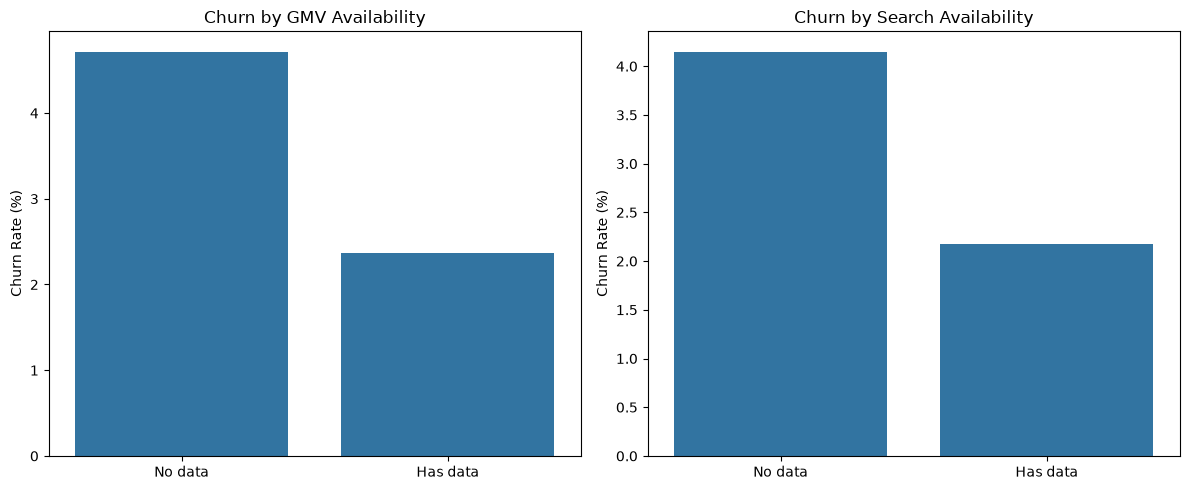

In [62]:
# Calculate churn rate by data availability
def availability_churn(data, feature):
    result = (
        data.groupby(feature, observed=True)
        .agg(
            merchant_months=("churn_next_30d", "size"),
            churn_count=("churn_next_30d", "sum"),
            churn_rate=("churn_next_30d", "mean")
        )
        .reset_index()
    )

    result["availability"] = result[feature].map({
        0: "No data",
        1: "Has data"
    })

    result["churn_rate_pct"] = result["churn_rate"] * 100

    return result[
        ["availability", "merchant_months",
         "churn_count", "churn_rate_pct"]
    ]


# GMV availability
gmv_availability = availability_churn(
    train_eda, "has_gmv_data"
)

# Search availability
search_availability = availability_churn(
    train_eda, "has_search_data"
)

print("CHURN BY GMV DATA AVAILABILITY")
display(gmv_availability)

print("CHURN BY SEARCH DATA AVAILABILITY")
display(search_availability)


# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=gmv_availability,
    x="availability",
    y="churn_rate_pct",
    ax=axes[0]
)
axes[0].set_title("Churn by GMV Availability")
axes[0].set_xlabel("")
axes[0].set_ylabel("Churn Rate (%)")

sns.barplot(
    data=search_availability,
    x="availability",
    y="churn_rate_pct",
    ax=axes[1]
)
axes[1].set_title("Churn by Search Availability")
axes[1].set_xlabel("")
axes[1].set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

**Key findings:**

- Merchants without GMV records have a churn rate of 4.72%, approximately 1.99 times that of merchants with GMV data (2.37%).
- Merchants without Search Traffic records also show a higher churn rate (4.15%) than merchants with available data (2.17%).
- Data availability indicators may provide predictive information and should be retained as candidate features.

### 3. Business Activity Patterns Before Churn

In [63]:
# Select key activity features
key_features = [
    "gmv_growth_30d",
    "gmv_growth_60d",
    "searches_30d",
    "searches_60d",
    "orders_30d",
    "orders_60d",
    "searches_growth_30d",
    "searches_growth_60d",
    "orders_growth_30d",
    "orders_growth_60d"
]

# Compare median values by churn status
activity_median = (
    train_eda
    .groupby("churn_next_30d")[key_features]
    .median()
    .T
    .rename(columns={
        0: "Non-churn",
        1: "Churn"
    })
)

# Add the number of available observations
activity_count = (
    train_eda
    .groupby("churn_next_30d")[key_features]
    .count()
    .T
    .rename(columns={
        0: "Non-churn count",
        1: "Churn count"
    })
)

activity_summary = activity_count.join(activity_median)

display(activity_summary.round(3))

churn_next_30d,Non-churn count,Churn count,Non-churn,Churn
gmv_growth_30d,13935,331,-0.027,-0.158
gmv_growth_60d,13535,324,-0.006,-0.067
searches_30d,12424,276,1854.500,677.500
searches_60d,12118,251,4045.500,2436.000
orders_30d,12424,276,2.000,0.000
orders_60d,12118,251,4.000,2.000
searches_growth_30d,12118,251,0.017,-0.111
searches_growth_60d,11761,228,-0.029,-0.186
orders_growth_30d,7138,137,-0.049,-0.333
orders_growth_60d,7713,147,-0.090,-0.298


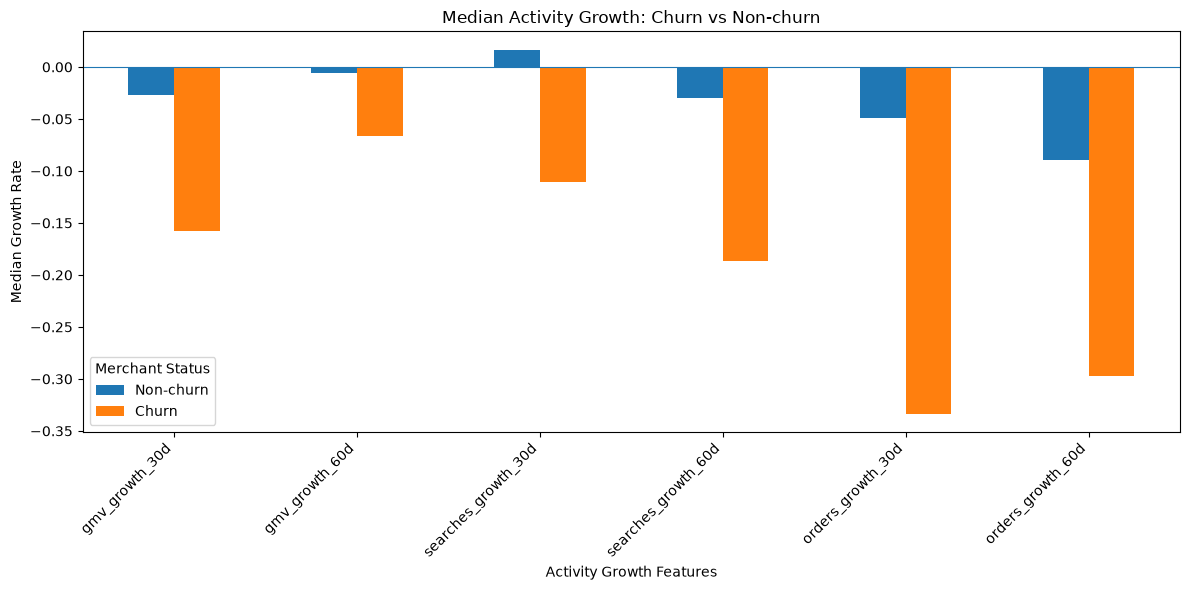

In [64]:
growth_features = [
    "gmv_growth_30d",
    "gmv_growth_60d",
    "searches_growth_30d",
    "searches_growth_60d",
    "orders_growth_30d",
    "orders_growth_60d"
]

growth_median = (
    train_eda
    .groupby("churn_next_30d")[growth_features]
    .median()
    .T
    .rename(columns={
        0: "Non-churn",
        1: "Churn"
    })
)

growth_median.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Median Activity Growth: Churn vs Non-churn")
plt.xlabel("Activity Growth Features")
plt.ylabel("Median Growth Rate")
plt.xticks(rotation=45, ha="right")
plt.axhline(0, linewidth=0.8)
plt.legend(title="Merchant Status")
plt.tight_layout()
plt.show()

**Key findings:**

- Merchants who churn in the following month generally show weaker business activity than non-churned merchants.
- The median GMV growth rate over 30 days is -15.8% for churned merchants, compared with -2.7% for non-churned merchants.
- Churned merchants also show lower Search Traffic volume and more negative Search growth rates.
- Order activity provides another potential churn signal. The median order count over 30 days is zero among churned merchants, compared with two among non-churned merchants.
- These patterns suggest that declining GMV, Search Traffic, and order activity may be useful predictive signals.

### 4. Highly skewed features

In [65]:
# Exclude binary flags from skewness analysis
binary_features = [
    "has_search_data",
    "has_gmv_data",
    "multi_currency_flag"
]

continuous_features = [
    col for col in numeric_features
    if col not in binary_features
]

# Calculate distribution statistics
skewness_summary = pd.DataFrame({
    "non_null_count": train_eda[continuous_features].count(),
    "skewness": train_eda[continuous_features].skew(),
    "min": train_eda[continuous_features].min(),
    "median": train_eda[continuous_features].median(),
    "max": train_eda[continuous_features].max()
})

# Classify skewness
def classify_skewness(value):
    if abs(value) < 0.5:
        return "Approximately symmetric"
    elif abs(value) < 1:
        return "Moderately skewed"
    else:
        return "Highly skewed"

skewness_summary["skewness_level"] = (
    skewness_summary["skewness"]
    .apply(classify_skewness)
)

# Sort by absolute skewness
skewness_summary["abs_skewness"] = (
    skewness_summary["skewness"].abs()
)

skewness_summary = skewness_summary.sort_values(
    "abs_skewness",
    ascending=False
)

display(skewness_summary.round(3))

NameError: name 'numeric_features' is not defined

#### 1.2. Outliers detection

In [ ]:
# Calculate percentile statistics for continuous features
percentile_summary = train_eda[continuous_features].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).T

percentile_summary = percentile_summary[
    ["count", "mean", "50%", "75%", "90%", "95%", "99%", "max"]
]

# Sort by maximum-to-median ratio
percentile_summary["max_median_ratio"] = (
    percentile_summary["max"]
    / percentile_summary["50%"].replace(0, np.nan)
)

percentile_summary = percentile_summary.sort_values(
    "max_median_ratio",
    ascending=False
)

display(percentile_summary.round(3))

,count,mean,50%,75%,90%,95%,99%,max,max_median_ratio
searches_growth_30d,12369.0,5.417,0.015,0.210,0.606,1.184,6.574,3.611550e+04,2467892.500
orders_30d,12700.0,104.667,2.000,24.000,151.000,362.000,1909.020,2.828000e+04,14140.000
orders_60d,12369.0,218.049,4.000,53.000,321.200,759.600,3824.400,3.359500e+04,8398.750
add_carts_30d,12700.0,484.787,16.000,143.000,709.100,1696.300,7591.320,1.264990e+05,7906.188
add_carts_60d,12369.0,1003.788,36.000,306.000,1467.200,3425.600,16036.240,2.597320e+05,7214.778
searches_30d,12700.0,23246.731,1818.000,9255.500,34858.100,79077.050,340987.390,8.332471e+06,4583.317
product_clicks_30d,12700.0,3057.645,155.000,1129.250,4850.200,11213.000,52064.880,7.024810e+05,4532.135
searches_60d,12369.0,46542.706,4004.000,19142.000,70276.800,157958.400,666921.480,1.602954e+07,4003.381
search_clicks_30d,12700.0,1624.727,96.000,667.000,2698.100,6069.600,26674.090,3.449180e+05,3592.896
gmv_60d,14339.0,510715.764,68194.652,285922.250,952879.297,1935881.989,6476700.391,2.398350e+08,3516.918


In [ ]:
growth_features = [
    "gmv_growth_30d",
    "gmv_growth_60d",
    "searches_growth_30d",
    "searches_growth_60d",
    "orders_growth_30d",
    "orders_growth_60d"
]

# Inspect the 10 largest values for each growth feature
for feature in growth_features:
    print(f"\nTop 10 extreme values: {feature}")

    display(
        train_eda[
            ["shop_key", "snapshot_month", "churn_next_30d", feature]
        ]
        .dropna()
        .nlargest(10, feature)
        .round(3)
    )


Top 10 extreme values: gmv_growth_30d


C:\Users\HP\AppData\Local\Temp\ipykernel_9040\2728681476.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,shop_key,snapshot_month,churn_next_30d,gmv_growth_30d
23161,store-q3bjhy3s.myshopify.com,2026-07-01,0,44690.249
22028,store-kjvfpwod.myshopify.com,2026-07-01,0,19577.779
24528,store-oad8lalw.myshopify.com,2026-06-01,0,6871.508
22290,store-dsqazavh.myshopify.com,2026-06-01,0,2524.885
24006,store-e2i2rzch.myshopify.com,2026-06-01,0,2444.443
25135,store-0ve9aybe.myshopify.com,2026-07-01,0,2278.800
25151,store-xutmehpo.myshopify.com,2026-07-01,0,1257.176
15574,store-lavd2zj1.myshopify.com,2026-07-01,0,776.674
25433,store-jah65o1v.myshopify.com,2026-07-01,0,743.696
6163,store-m81v2q80.myshopify.com,2026-06-01,0,418.350



Top 10 extreme values: gmv_growth_60d


C:\Users\HP\AppData\Local\Temp\ipykernel_9040\2728681476.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,shop_key,snapshot_month,churn_next_30d,gmv_growth_60d
3244,store-uqo3yot0.myshopify.com,2026-06-01,0,11080.654
8814,store-e2i2rzch.myshopify.com,2026-07-01,0,2466.927
7815,store-njcfp2h4.myshopify.com,2026-06-01,0,1490.837
5947,store-lfgaxm3y.myshopify.com,2026-06-01,0,709.428
15574,store-lavd2zj1.myshopify.com,2026-07-01,0,347.783
13844,store-t7dxgyga.myshopify.com,2026-07-01,0,271.826
13014,store-d78lph60.myshopify.com,2026-06-01,0,191.094
1065,store-fvs6vhp7.myshopify.com,2026-06-01,0,151.727
17497,store-sa5sw4f5.myshopify.com,2026-06-01,0,130.847
17156,store-1q5y3914.myshopify.com,2026-07-01,0,113.420


... (8 outputs left out)

,shop_key,snapshot_month,churn_next_30d,orders_growth_30d
10657,store-2lqa22es.myshopify.com,2026-07-01,0,453.500
1794,store-1q5y3914.myshopify.com,2026-06-01,0,136.500
4202,store-l8l9jh6h.myshopify.com,2026-06-01,0,85.000
13301,store-ecq1ktvs.myshopify.com,2026-07-01,0,60.000
1259,store-lzqgzga9.myshopify.com,2026-07-01,0,27.000
8246,store-zld288pm.myshopify.com,2026-07-01,0,21.000
9498,store-ay8msce2.myshopify.com,2026-07-01,0,18.000
703,store-o6jkz3b6.myshopify.com,2026-07-01,0,14.297
14331,store-9t96tsvy.myshopify.com,2026-06-01,0,14.000
283,store-c230sczl.myshopify.com,2026-06-01,0,13.000



Top 10 extreme values: orders_growth_60d


C:\Users\HP\AppData\Local\Temp\ipykernel_9040\2728681476.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,shop_key,snapshot_month,churn_next_30d,orders_growth_60d
10657,store-2lqa22es.myshopify.com,2026-07-01,0,910.0
7048,store-vwvfh1t2.myshopify.com,2026-06-01,0,742.0
17156,store-1q5y3914.myshopify.com,2026-07-01,0,296.0
15910,store-l8l9jh6h.myshopify.com,2026-07-01,0,276.0
14395,store-ld9bgig3.myshopify.com,2026-06-01,0,265.0
25151,store-xutmehpo.myshopify.com,2026-07-01,0,58.0
11736,store-saeu91id.myshopify.com,2026-06-01,0,36.0
5077,store-ewj7lya5.myshopify.com,2026-06-01,0,33.0
7677,store-75jqacci.myshopify.com,2026-07-01,0,28.5
1259,store-lzqgzga9.myshopify.com,2026-07-01,0,28.0


In [ ]:
# Analyze extreme growth values
growth_extreme_summary = []

for feature in growth_features:
    p99 = train_eda[feature].quantile(0.99)

    extreme_data = train_eda[
        train_eda[feature] > p99
    ]

    growth_extreme_summary.append({
        "feature": feature,
        "p99_threshold": p99,
        "extreme_count": len(extreme_data),
        "extreme_pct": len(extreme_data) / train_eda[feature].notna().sum() * 100,
        "non_churn_count": (extreme_data["churn_next_30d"] == 0).sum(),
        "churn_count": (extreme_data["churn_next_30d"] == 1).sum()
    })

growth_extreme_summary = pd.DataFrame(growth_extreme_summary)

display(growth_extreme_summary.round(3))

,feature,p99_threshold,extreme_count,extreme_pct,non_churn_count,churn_count
0,gmv_growth_30d,8.311,143,1.002,141,2
1,gmv_growth_60d,4.358,139,1.003,136,3
2,searches_growth_30d,6.574,124,1.003,121,3
3,searches_growth_60d,4.427,120,1.001,119,1
4,orders_growth_30d,5.000,71,0.976,71,0
5,orders_growth_60d,5.000,66,0.840,65,1


**Key findings:**

- Most numerical features exhibit right-skewed distributions, particularly GMV, MRR, Search Traffic, and order activity volumes.
- Growth features contain extreme positive values, potentially caused by very small baseline activity in the previous period.
- Approximately 1% of observations exceed the 99th percentile for each growth feature. These observations are not exclusively associated with churn.
- Log transformation is a candidate preprocessing step for non-negative volume and monetary features.
- Growth rates should not be directly log-transformed because they can contain negative values. Clipping at the 99th percentile will be evaluated as an alternative during model development.
- No observations are removed solely because of extreme values during EDA.

### 5. Impact of missing values 

In [ ]:
# Identify missing values in training data
missing_summary = pd.DataFrame({
    "missing_count": train_eda.isna().sum(),
    "missing_pct": train_eda.isna().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

display(missing_summary.round(2))

,missing_count,missing_pct
orders_growth_30d,9906,57.66
orders_growth_60d,9321,54.25
add_carts_growth_30d,7932,46.17
cart_to_order_rate_30d,7862,45.76
add_carts_growth_60d,7720,44.93
cart_to_order_rate_60d,7504,43.68
product_clicks_growth_60d,7045,41.00
search_clicks_growth_60d,7045,41.00
product_clicks_growth_30d,7029,40.91
search_clicks_growth_30d,7029,40.91


In [ ]:
# Compare churn rates between missing and available observations

missing_churn_results = []

for feature in missing_summary.index:
    missing_mask = train_eda[feature].isna()

    missing_group = train_eda[missing_mask]
    available_group = train_eda[~missing_mask]

    missing_churn_results.append({
        "feature": feature,
        "missing_count": len(missing_group),
        "missing_churn_rate": missing_group["churn_next_30d"].mean() * 100,
        "available_count": len(available_group),
        "available_churn_rate": available_group["churn_next_30d"].mean() * 100,
        "rate_difference_pp": (
            missing_group["churn_next_30d"].mean()
            - available_group["churn_next_30d"].mean()
        ) * 100
    })

missing_churn_summary = pd.DataFrame(missing_churn_results)

missing_churn_summary = missing_churn_summary.sort_values(
    "rate_difference_pp",
    ascending=False
)

display(missing_churn_summary.round(2))

,feature,missing_count,missing_churn_rate,available_count,available_churn_rate,rate_difference_pp
33,mrr_growth_rate,228,16.23,16953,2.51,13.72
12,searches_growth_60d,5192,4.51,11989,1.90,2.61
19,searches_60d,4812,4.38,12369,2.03,2.36
20,search_clicks_60d,4812,4.38,12369,2.03,2.36
17,searches_growth_30d,4812,4.38,12369,2.03,2.36
14,search_click_rate_60d,4812,4.38,12369,2.03,2.36
13,orders_60d,4812,4.38,12369,2.03,2.36
16,add_carts_60d,4812,4.38,12369,2.03,2.36
18,search_to_product_click_rate_60d,4812,4.38,12369,2.03,2.36
15,product_clicks_60d,4812,4.38,12369,2.03,2.36


In [ ]:
# Investigate why mrr_growth_rate is missing

mrr_growth_missing = train_eda[
    train_eda["mrr_growth_rate"].isna()
].copy()

mrr_growth_missing_summary = pd.DataFrame({
    "metric": [
        "Missing mrr_growth_rate",
        "BOM MRR = 0",
        "BOM MRR > 0",
        "BOM MRR is missing",
    ],
    "count": [
        len(mrr_growth_missing),
        (mrr_growth_missing["bom_mrr"] == 0).sum(),
        (mrr_growth_missing["bom_mrr"] > 0).sum(),
        mrr_growth_missing["bom_mrr"].isna().sum(),
    ]
})

display(mrr_growth_missing_summary)

,metric,count
0,Missing mrr_growth_rate,228
1,BOM MRR = 0,228
2,BOM MRR > 0,0
3,BOM MRR is missing,0


**Key findings:**

- Missingness is associated with higher churn rates across several feature groups.
- Merchants without GMV or Search Traffic records have approximately 2 percentage points higher churn rates than merchants with available records.
- Missing `mrr_growth_rate` is particularly informative: its missing group has a churn rate of 16.23%, compared with 2.51% for the available group.
- All 228 missing `mrr_growth_rate` observations have `bom_mrr = 0`. Therefore, this is structural missingness caused by an undefined growth calculation rather than missing source data.
- During modeling, missing values will be handled within the preprocessing pipeline. A separate indicator for `bom_mrr = 0` may also be evaluated.

### 6. Stability of churn

In [ ]:
# Compare monthly churn rates in the training period

monthly_churn = (
    train_eda.groupby("snapshot_month")
    .agg(
        merchant_months=("churn_next_30d", "size"),
        churn_count=("churn_next_30d", "sum"),
        churn_rate=("churn_next_30d", "mean")
    )
    .reset_index()
)

monthly_churn["churn_rate_pct"] = monthly_churn["churn_rate"] * 100

display(
    monthly_churn[
        ["snapshot_month", "merchant_months", "churn_count", "churn_rate_pct"]
    ].round(2)
)

C:\Users\HP\AppData\Local\Temp\ipykernel_9040\1165242661.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,snapshot_month,merchant_months,churn_count,churn_rate_pct
0,2026-06-01,8669,247,2.85
1,2026-07-01,8512,215,2.53


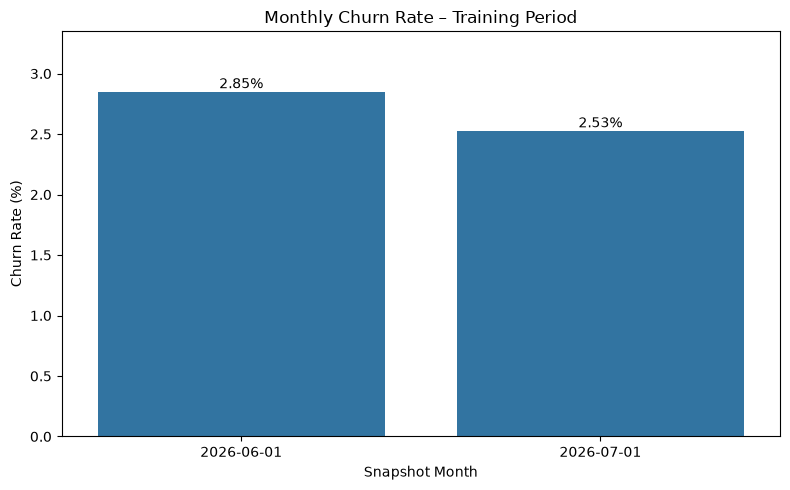

In [ ]:
# Visualize

plt.figure(figsize=(8, 5))

sns.barplot(
    data=monthly_churn,
    x="snapshot_month",
    y="churn_rate_pct"
)

plt.title("Monthly Churn Rate – Training Period")
plt.xlabel("Snapshot Month")
plt.ylabel("Churn Rate (%)")

for i, row in monthly_churn.iterrows():
    plt.text(
        i,
        row["churn_rate_pct"] + 0.03,
        f'{row["churn_rate_pct"]:.2f}%',
        ha="center"
    )

plt.ylim(0, monthly_churn["churn_rate_pct"].max() + 0.5)
plt.tight_layout()
plt.show()

**Key findings:**

- The churn rate decreased slightly from 2.85% in June 2026 to 2.53% in July 2026, a decline of 0.32 percentage points.
- Despite the small decrease, the churn rate remained within a relatively narrow range of 2.5%–2.9% across the training period.
- This suggests that the target distribution was relatively stable between the two training months.
- However, only two months are available for training, so this observation is insufficient to establish long-term churn stability.

## C. Modelling

### 1. Define features, target and groups

In [ ]:
TARGET = "churn_next_30d"

EXCLUDE_COLUMNS = [
    "shop_key",          # Used only for grouped cross-validation
    "snapshot_month",    # Excluded from baseline features
    "split",             # Dataset partition indicator
    TARGET
]

# Training data: June + July only
X_train = train_eda.drop(columns=EXCLUDE_COLUMNS)
y_train = train_eda[TARGET]
groups_train = train_eda["shop_key"]

# Inspect feature structure
print("Training feature shape:", X_train.shape)
print("Target shape:", y_train.shape)
print("\nFeature data types:")
print(X_train.dtypes.value_counts())

print("\nCategorical features:")
print(X_train.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumeric features:")
print(X_train.select_dtypes(include=["number"]).columns.tolist())

print("\nTarget distribution:")
print(y_train.value_counts())

Training feature shape: (17181, 44)
Target shape: (17181,)

Feature data types:
float64     36
int64        4
str          2
category     1
category     1
Name: count, dtype: int64

Categorical features:
['mrr_movement_type', 'gmv_currency_code', 'tenure_group', 'mrr_group']

Numeric features:
['tenure_months', 'bom_mrr', 'eom_mrr', 'mrr_change', 'mrr_growth_rate', 'has_search_data', 'searches_30d', 'product_clicks_30d', 'search_clicks_30d', 'add_carts_30d', 'orders_30d', 'gmv_30d', 'gmv_60d', 'gmv_growth_30d', 'gmv_growth_60d', 'has_gmv_data', 'multi_currency_flag', 'searches_60d', 'product_clicks_60d', 'search_clicks_60d', 'add_carts_60d', 'orders_60d', 'searches_growth_30d', 'product_clicks_growth_30d', 'search_clicks_growth_30d', 'add_carts_growth_30d', 'orders_growth_30d', 'searches_growth_60d', 'product_clicks_growth_60d', 'search_clicks_growth_60d', 'add_carts_growth_60d', 'orders_growth_60d', 'search_to_product_click_rate_30d', 'search_click_rate_30d', 'product_click_to_cart_ra

C:\Users\HP\AppData\Local\Temp\ipykernel_9040\1705641688.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_train.select_dtypes(include=["object", "category"]).columns.tolist())


### 2. Remove EDA-only features from modeling

In [ ]:
EDA_ONLY_COLUMNS = [
    "tenure_group",
    "mrr_group"
]

X_train = X_train.drop(columns=EDA_ONLY_COLUMNS)

# Identify feature groups
binary_features = [
    "has_search_data",
    "has_gmv_data",
    "multi_currency_flag"
]

categorical_features = [
    "mrr_movement_type",
    "gmv_currency_code"
]

numeric_features = [
    col for col in X_train.select_dtypes(include=["number"]).columns
    if col not in binary_features
]

print("Total features:", X_train.shape[1])
print("Numeric features:", len(numeric_features))
print("Binary features:", len(binary_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical values:")
for feature in categorical_features:
    print(f"\n{feature}:")
    print(X_train[feature].value_counts(dropna=False))

Total features: 42
Numeric features: 37
Binary features: 3
Categorical features: 2

Categorical values:

mrr_movement_type:
mrr_movement_type
unchanged    16826
new_mrr        228
increased       97
decreased       30
Name: count, dtype: int64

gmv_currency_code:
gmv_currency_code
USD    5949
NaN    2453
GBP    1833
EUR    1739
AUD    1378
       ... 
RSD       2
NGN       2
GEL       2
BWP       1
KRW       1
Name: count, Length: 68, dtype: int64


### 3. Inspect missing values and binary features

In [ ]:
# Missing values by feature group
missing_by_group = pd.DataFrame({
    "feature_group": (
        ["Numeric"] * len(numeric_features)
        + ["Binary"] * len(binary_features)
        + ["Categorical"] * len(categorical_features)
    ),
    "feature": numeric_features + binary_features + categorical_features,
    "missing_count": [
        X_train[col].isna().sum()
        for col in numeric_features + binary_features + categorical_features
    ]
})

display(
    missing_by_group[
        missing_by_group["missing_count"] > 0
    ].sort_values("missing_count", ascending=False)
)

# Check binary feature values
print("\nBinary feature distributions:")

for feature in binary_features:
    print(f"\n{feature}:")
    print(X_train[feature].value_counts(dropna=False))

,feature_group,feature,missing_count
23,Numeric,orders_growth_30d,9906
28,Numeric,orders_growth_60d,9321
22,Numeric,add_carts_growth_30d,7932
32,Numeric,cart_to_order_rate_30d,7862
27,Numeric,add_carts_growth_60d,7720
36,Numeric,cart_to_order_rate_60d,7504
25,Numeric,product_clicks_growth_60d,7045
26,Numeric,search_clicks_growth_60d,7045
21,Numeric,search_clicks_growth_30d,7029
20,Numeric,product_clicks_growth_30d,7029



Binary feature distributions:

has_search_data:
has_search_data
1    12700
0     4481
Name: count, dtype: int64

has_gmv_data:
has_gmv_data
1    14828
0     2353
Name: count, dtype: int64

multi_currency_flag:
multi_currency_flag
0    17081
1      100
Name: count, dtype: int64


### 4. Prepare preprocessing components

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
import numpy as np

# Numeric features to log-transform
log_features = [
    "bom_mrr",
    "eom_mrr",
    "gmv_30d",
    "gmv_60d",
    "searches_30d",
    "product_clicks_30d",
    "search_clicks_30d",
    "add_carts_30d",
    "orders_30d",
    "searches_60d",
    "product_clicks_60d",
    "search_clicks_60d",
    "add_carts_60d",
    "orders_60d"
]

# Other numeric features
other_numeric_features = [
    col for col in numeric_features
    if col not in log_features
]

print("Log-transformed features:", len(log_features))
print("Other numeric features:", len(other_numeric_features))
print("Binary features:", len(binary_features))
print("Categorical features:", len(categorical_features))
print("\nOther numeric features:")
print(other_numeric_features)

Log-transformed features: 14
Other numeric features: 23
Binary features: 3
Categorical features: 2

Other numeric features:
['tenure_months', 'mrr_change', 'mrr_growth_rate', 'gmv_growth_30d', 'gmv_growth_60d', 'searches_growth_30d', 'product_clicks_growth_30d', 'search_clicks_growth_30d', 'add_carts_growth_30d', 'orders_growth_30d', 'searches_growth_60d', 'product_clicks_growth_60d', 'search_clicks_growth_60d', 'add_carts_growth_60d', 'orders_growth_60d', 'search_to_product_click_rate_30d', 'search_click_rate_30d', 'product_click_to_cart_rate_30d', 'cart_to_order_rate_30d', 'search_to_product_click_rate_60d', 'search_click_rate_60d', 'product_click_to_cart_rate_60d', 'cart_to_order_rate_60d']


### 5. Build preprocessing transformer

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
import numpy as np

# Ensure categorical columns support the "Missing" category
X_train[categorical_features] = (
    X_train[categorical_features].astype("object")
)

# Pipeline for non-negative numeric features
log_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

# Pipeline for other numeric features
other_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine all preprocessing branches
preprocessor = ColumnTransformer(
    transformers=[
        ("log_numeric", log_numeric_pipeline, log_features),
        ("other_numeric", other_numeric_pipeline, other_numeric_features),
        ("binary", "passthrough", binary_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("missing_indicators", MissingIndicator(features="all"), numeric_features)
    ],
    remainder="drop"
)

print("Preprocessing transformer created successfully!")
print("Total input features:", X_train.shape[1])
print("Log numeric:", len(log_features))
print("Other numeric:", len(other_numeric_features))
print("Binary:", len(binary_features))
print("Categorical:", len(categorical_features))
print("Missing indicators:", len(numeric_features))

Preprocessing transformer created successfully!
Total input features: 42
Log numeric: 14
Other numeric: 23
Binary: 3
Categorical: 2
Missing indicators: 37


### 6. Grouped Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Match merchant IDs to the exact row order in X_train
groups = train_eda.loc[X_train.index, "shop_key"]

# Set up grouped stratified cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Training samples:", len(X_train))
print("Unique merchants:", groups.nunique())
print("Number of CV folds:", cv.get_n_splits())
print("Churn rate:", round(y_train.mean() * 100, 2), "%")

Training samples: 17181
Unique merchants: 8768
Number of CV folds: 5
Churn rate: 2.69 %


### 7. Logistic Regression

#### 7.1. Logistic Regression baseline pipeline

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")
print("Class weight:", logistic_pipeline.named_steps["classifier"].class_weight)
print("Maximum iterations:", logistic_pipeline.named_steps["classifier"].max_iter)

Logistic Regression pipeline created successfully!
Class weight: balanced
Maximum iterations: 2000


#### 7.2. Cross-validation for Logistic Regression

In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

def calculate_top_k_metrics(y_true, y_score, k_percent):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    # Select the top K% merchants with the highest churn probability
    k = max(1, int(np.ceil(len(y_true) * k_percent)))
    top_indices = np.argsort(y_score)[-k:]

    precision = y_true[top_indices].mean()
    recall = y_true[top_indices].sum() / y_true.sum()
    lift = precision / y_true.mean()

    return precision, recall, lift


logistic_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    # Split data
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    # Create a fresh pipeline for each fold
    model = clone(logistic_pipeline)

    # Train and predict
    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    # Calculate ranking metrics
    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    logistic_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

logistic_cv_results = pd.DataFrame(logistic_results)

display(logistic_cv_results.round(4))

print("\nMean CV performance:")
display(
    logistic_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.6776,0.1092,0.1047,0.1957,3.9085,0.0814,0.3043,3.0399
1,2,0.6466,0.0599,0.0756,0.1413,2.8228,0.0640,0.2391,2.3885
2,3,0.6772,0.0710,0.0930,0.1739,3.4742,0.0785,0.2935,2.9314
3,4,0.6605,0.0715,0.0698,0.1290,2.5784,0.0523,0.1935,1.9338
4,5,0.6862,0.1229,0.1221,0.2258,4.5109,0.0901,0.3333,3.3295



Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.6696,0.0869,0.0930,0.1731,3.4590,0.0733,0.2728,2.7246
std,0.0159,0.0274,0.0214,0.0395,0.7888,0.0150,0.0559,0.5582


### 8. Random Forest

#### 8.1. Build Random Forest baseline pipeline

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest baseline pipeline created successfully!")
print("Number of trees:", 300)
print("Class weight:", "balanced_subsample")
print("Minimum samples per leaf:", 5)

Random Forest baseline pipeline created successfully!
Number of trees: 300
Class weight: balanced_subsample
Minimum samples per leaf: 5


#### 8.2. Cross-validation for Random Forest

In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

rf_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = clone(random_forest_pipeline)

    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    rf_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

rf_cv_results = pd.DataFrame(rf_results)

print("Random Forest - Fold results:")
display(rf_cv_results.round(4))

print("\nRandom Forest - Mean CV performance:")
display(
    rf_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

Random Forest - Fold results:


,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.7075,0.0984,0.0988,0.1848,3.6914,0.0843,0.3152,3.1485
1,2,0.6682,0.0809,0.1047,0.1957,3.9085,0.0698,0.2609,2.6057
2,3,0.7242,0.0668,0.0523,0.0978,1.9542,0.0610,0.2283,2.2800
3,4,0.6877,0.0582,0.0640,0.1183,2.3635,0.0640,0.2366,2.3635
4,5,0.7028,0.0683,0.0756,0.1398,2.7924,0.0669,0.2473,2.4702



Random Forest - Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.6981,0.0745,0.0791,0.1473,2.9420,0.0692,0.2576,2.5736
std,0.0212,0.0156,0.0224,0.0421,0.8409,0.0091,0.0344,0.3437


### 9. HistGradientBoostingClassifier

#### 9.1. Build preprocessing for HistGradientBoosting

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
import numpy as np

# Numeric features with log transformation
hgb_log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

# Other numeric features
hgb_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: dense One-Hot Encoding
hgb_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing branches
hgb_preprocessor = ColumnTransformer(
    transformers=[
        ("log_numeric", hgb_log_pipeline, log_features),
        ("other_numeric", hgb_numeric_pipeline, other_numeric_features),
        ("binary", "passthrough", binary_features),
        ("categorical", hgb_categorical_pipeline, categorical_features),
        ("missing_indicators", MissingIndicator(features="all"), numeric_features)
    ],
    remainder="drop"
)

print("HistGradientBoosting preprocessor created successfully!")
print("Output format: Dense")

HistGradientBoosting preprocessor created successfully!
Output format: Dense


#### 9.2. HistGradientBoosting baseline pipeline

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

hgb_pipeline = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

print("HistGradientBoosting pipeline created successfully!")
print("Learning rate:", 0.05)
print("Maximum iterations:", 200)
print("Maximum leaf nodes:", 15)
print("Class weight:", "balanced")

HistGradientBoosting pipeline created successfully!
Learning rate: 0.05
Maximum iterations: 200
Maximum leaf nodes: 15
Class weight: balanced


#### 9.3. Cross-validation for HistGradientBoosting

In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

hgb_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = clone(hgb_pipeline)

    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    hgb_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

hgb_cv_results = pd.DataFrame(hgb_results)

print("HistGradientBoosting - Fold results:")
display(hgb_cv_results.round(4))

print("\nHistGradientBoosting - Mean CV performance:")
display(
    hgb_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

HistGradientBoosting - Fold results:


,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.7154,0.1151,0.1337,0.2500,4.9942,0.0872,0.3261,3.2571
1,2,0.6957,0.0822,0.1279,0.2391,4.7770,0.0959,0.3587,3.5828
2,3,0.7373,0.0809,0.1221,0.2283,4.5599,0.0901,0.3370,3.3656
3,4,0.6802,0.0900,0.1047,0.1935,3.8676,0.0843,0.3118,3.1156
4,5,0.7261,0.1111,0.1337,0.2473,4.9405,0.0959,0.3548,3.5443



HistGradientBoosting - Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.7109,0.0958,0.1244,0.2317,4.6278,0.0907,0.3377,3.3731
std,0.0230,0.0162,0.0121,0.0229,0.4574,0.0052,0.0196,0.1956


#### 9.4. Build unweighted HistGradientBoosting pipeline

In [ ]:
hgb_unweighted_pipeline = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        class_weight=None,
        random_state=42
    ))
])

print("Unweighted HistGradientBoosting pipeline created successfully!")
print("Class weight:", None)

Unweighted HistGradientBoosting pipeline created successfully!
Class weight: None


In [ ]:
# Cross-validation for unweighted HistGradientBoosting
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

hgb_unweighted_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = clone(hgb_unweighted_pipeline)

    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    hgb_unweighted_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

hgb_unweighted_cv_results = pd.DataFrame(hgb_unweighted_results)

print("Unweighted HistGradientBoosting - Fold results:")
display(hgb_unweighted_cv_results.round(4))

print("\nUnweighted HistGradientBoosting - Mean CV performance:")
display(
    hgb_unweighted_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

Unweighted HistGradientBoosting - Fold results:


,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.7063,0.1100,0.1163,0.2174,4.3428,0.0814,0.3043,3.0399
1,2,0.6871,0.1082,0.1337,0.2500,4.9942,0.0930,0.3478,3.4742
2,3,0.7505,0.0859,0.1163,0.2174,4.3428,0.0930,0.3478,3.4742
3,4,0.7002,0.0849,0.0988,0.1828,3.6527,0.0901,0.3333,3.3304
4,5,0.7387,0.1297,0.1453,0.2688,5.3701,0.1105,0.4086,4.0813



Unweighted HistGradientBoosting - Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.7166,0.1037,0.1221,0.2273,4.5405,0.0936,0.3484,3.48
std,0.0268,0.0187,0.0179,0.0332,0.6634,0.0106,0.0381,0.38


In [ ]:
# Compare weighted and unweighted HistGradientBoosting

imbalance_comparison = pd.DataFrame([
    {
        "strategy": "Class weight: balanced",
        "roc_auc": hgb_cv_results["roc_auc"].mean(),
        "pr_auc": hgb_cv_results["pr_auc"].mean(),
        "precision_at_5%": hgb_cv_results["precision_at_5%"].mean(),
        "recall_at_5%": hgb_cv_results["recall_at_5%"].mean(),
        "lift_at_5%": hgb_cv_results["lift_at_5%"].mean(),
    },
    {
        "strategy": "No class weighting",
        "roc_auc": hgb_unweighted_cv_results["roc_auc"].mean(),
        "pr_auc": hgb_unweighted_cv_results["pr_auc"].mean(),
        "precision_at_5%": hgb_unweighted_cv_results["precision_at_5%"].mean(),
        "recall_at_5%": hgb_unweighted_cv_results["recall_at_5%"].mean(),
        "lift_at_5%": hgb_unweighted_cv_results["lift_at_5%"].mean(),
    }
])

display(imbalance_comparison.round(4))

,strategy,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%
0,Class weight: balanced,0.7109,0.0958,0.1244,0.2317,4.6278
1,No class weighting,0.7166,0.1037,0.1221,0.2273,4.5405


#### 10. Threshold tuning

#### 10.1. Generate out-of-fold probabilities

In [ ]:
from sklearn.model_selection import cross_val_predict
import numpy as np

oof_probabilities = cross_val_predict(
    hgb_unweighted_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("OOF predictions generated successfully!")
print("Number of predictions:", len(oof_probabilities))
print("Minimum probability:", round(oof_probabilities.min(), 4))
print("Maximum probability:", round(oof_probabilities.max(), 4))

OOF predictions generated successfully!
Number of predictions: 17181
Minimum probability: 0.004
Maximum probability: 0.5131


#### 10.2. Evaluate different classification thresholds

In [ ]:
from sklearn.metrics import precision_score, recall_score, fbeta_score

threshold_results = []

thresholds = list(np.arange(0.01, 0.201, 0.01)) + [0.50]

for threshold in thresholds:
    y_pred = (oof_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "predicted_churn": y_pred.sum(),
        "flagged_rate": y_pred.mean(),
        "precision": precision_score(y_train, y_pred, zero_division=0),
        "recall": recall_score(y_train, y_pred, zero_division=0),
        "f2_score": fbeta_score(
            y_train, y_pred, beta=2, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,threshold,predicted_churn,flagged_rate,precision,recall,f2_score
0,0.01,14419,0.8392,0.0302,0.9416,0.1337
1,0.02,7798,0.4539,0.0430,0.7251,0.1736
2,0.03,4359,0.2537,0.0608,0.5736,0.2135
3,0.04,2774,0.1615,0.0710,0.4264,0.2131
4,0.05,1577,0.0918,0.0951,0.3247,0.2190
5,0.06,1042,0.0606,0.1152,0.2597,0.2076
6,0.07,722,0.0420,0.1274,0.1991,0.1790
7,0.08,557,0.0324,0.1454,0.1753,0.1684
8,0.09,448,0.0261,0.1585,0.1537,0.1546
9,0.10,355,0.0207,0.1746,0.1342,0.1407


**Threshold Tuning**

The default classification threshold of 0.5 is unsuitable for this highly imbalanced churn prediction task. At this threshold, the model identifies almost no merchants as potential churners.

Threshold tuning was conducted using out-of-fold predictions from the training set to avoid evaluating thresholds on in-sample predictions.

The threshold of 0.05 achieved the highest F2-score (0.2190) among the tested thresholds:
- Precision: 9.51%
- Recall: 32.47%
- Flagged merchants: 1,577 (9.18%)

A threshold of 0.06 may be a more conservative alternative when intervention capacity is limited, flagging 6.06% of observations with 25.97% recall.

The threshold of 0.05 is retained as the primary candidate for subsequent evaluation.

In [ ]:
# Cross-validation for unweighted HistGradientBoosting
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

hgb_unweighted_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = clone(hgb_unweighted_pipeline)

    model.fit(X_tr, y_tr)
    y_score = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, y_score)
    pr_auc = average_precision_score(y_val, y_score)

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    hgb_unweighted_results.append({
        "fold": fold,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

hgb_unweighted_cv_results = pd.DataFrame(hgb_unweighted_results)

print("Unweighted HistGradientBoosting - Fold results:")
display(hgb_unweighted_cv_results.round(4))

print("\nUnweighted HistGradientBoosting - Mean CV performance:")
display(
    hgb_unweighted_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

Unweighted HistGradientBoosting - Fold results:


,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.7063,0.1100,0.1163,0.2174,4.3428,0.0814,0.3043,3.0399
1,2,0.6871,0.1082,0.1337,0.2500,4.9942,0.0930,0.3478,3.4742
2,3,0.7505,0.0859,0.1163,0.2174,4.3428,0.0930,0.3478,3.4742
3,4,0.7002,0.0849,0.0988,0.1828,3.6527,0.0901,0.3333,3.3304
4,5,0.7387,0.1297,0.1453,0.2688,5.3701,0.1105,0.4086,4.0813



Unweighted HistGradientBoosting - Mean CV performance:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.7166,0.1037,0.1221,0.2273,4.5405,0.0936,0.3484,3.48
std,0.0268,0.0187,0.0179,0.0332,0.6634,0.0106,0.0381,0.38


### 11. Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

print("Hyperparameter tuning tools imported successfully!")

Hyperparameter tuning tools imported successfully!


#### 11.1. HistGradientBoosting hyperparameter tuning

In [ ]:
param_grid = {
    "classifier__learning_rate": [0.03, 0.05],
    "classifier__max_iter": [150, 250],
    "classifier__max_leaf_nodes": [15],
    "classifier__l2_regularization": [1.0]
}

hgb_grid_search = GridSearchCV(
    estimator=hgb_unweighted_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=1,
    return_train_score=True
)

hgb_grid_search.fit(
    X_train,
    y_train,
    groups=groups
)

print("Best parameters:")
print(hgb_grid_search.best_params_)

print("\nBest mean CV PR-AUC:")
print(round(hgb_grid_search.best_score_, 4))

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters:
{'classifier__l2_regularization': 1.0, 'classifier__learning_rate': 0.03, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 15}

Best mean CV PR-AUC:
0.105


#### 11.2. Evaluate tuned HistGradientBoosting after tunning

In [ ]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

hgb_tuned_pipeline = clone(hgb_grid_search.best_estimator_)

hgb_tuned_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups),
    start=1
):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = clone(hgb_tuned_pipeline)
    model.fit(X_tr, y_tr)

    y_score = model.predict_proba(X_val)[:, 1]

    p5, r5, l5 = calculate_top_k_metrics(y_val, y_score, 0.05)
    p10, r10, l10 = calculate_top_k_metrics(y_val, y_score, 0.10)

    hgb_tuned_results.append({
        "fold": fold,
        "roc_auc": roc_auc_score(y_val, y_score),
        "pr_auc": average_precision_score(y_val, y_score),
        "precision_at_5%": p5,
        "recall_at_5%": r5,
        "lift_at_5%": l5,
        "precision_at_10%": p10,
        "recall_at_10%": r10,
        "lift_at_10%": l10
    })

hgb_tuned_cv_results = pd.DataFrame(hgb_tuned_results)

print("Tuned HistGradientBoosting - Fold results:")
display(hgb_tuned_cv_results.round(4))

print("\nTuned HistGradientBoosting - Mean and standard deviation:")
display(
    hgb_tuned_cv_results.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

Tuned HistGradientBoosting - Fold results:


,fold,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
0,1,0.7134,0.1127,0.1047,0.1957,3.9085,0.0814,0.3043,3.0399
1,2,0.6925,0.1149,0.1221,0.2283,4.5599,0.0872,0.3261,3.2571
2,3,0.7511,0.0879,0.1279,0.2391,4.7770,0.0872,0.3261,3.2571
3,4,0.7024,0.0802,0.0930,0.1720,3.4379,0.0959,0.3548,3.5453
4,5,0.7474,0.1290,0.1570,0.2903,5.7997,0.1105,0.4086,4.0813



Tuned HistGradientBoosting - Mean and standard deviation:


,roc_auc,pr_auc,precision_at_5%,recall_at_5%,lift_at_5%,precision_at_10%,recall_at_10%,lift_at_10%
mean,0.7214,0.1050,0.1209,0.2251,4.4966,0.0924,0.3440,3.4361
std,0.0265,0.0202,0.0245,0.0451,0.9010,0.0113,0.0403,0.4029


#### 11.3. Generate OOF predictions for tuned HistGradientBoosting

In [ ]:
oof_tuned_probabilities = cross_val_predict(
    hgb_tuned_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Tuned OOF predictions generated successfully!")
print("Number of predictions:", len(oof_tuned_probabilities))
print("Minimum probability:", round(oof_tuned_probabilities.min(), 4))
print("Maximum probability:", round(oof_tuned_probabilities.max(), 4))

Tuned OOF predictions generated successfully!
Number of predictions: 17181
Minimum probability: 0.0039
Maximum probability: 0.4502


#### 11.4. Evaluate thresholds for tuned HistGradientBoosting

In [ ]:
from sklearn.metrics import precision_score, recall_score, fbeta_score

tuned_threshold_results = []

thresholds = list(np.arange(0.01, 0.201, 0.01)) + [0.50]

for threshold in thresholds:
    y_pred = (oof_tuned_probabilities >= threshold).astype(int)

    tuned_threshold_results.append({
        "threshold": threshold,
        "predicted_churn": y_pred.sum(),
        "flagged_rate": y_pred.mean(),
        "precision": precision_score(
            y_train, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_train, y_pred, zero_division=0
        ),
        "f2_score": fbeta_score(
            y_train, y_pred, beta=2, zero_division=0
        )
    })

tuned_threshold_results_df = pd.DataFrame(tuned_threshold_results)

display(tuned_threshold_results_df.round(4))

,threshold,predicted_churn,flagged_rate,precision,recall,f2_score
0,0.01,15149,0.8817,0.0292,0.9567,0.1300
1,0.02,7834,0.4560,0.0437,0.7403,0.1766
2,0.03,4327,0.2518,0.0619,0.5801,0.2170
3,0.04,2684,0.1562,0.0738,0.4286,0.2184
4,0.05,1561,0.0909,0.0922,0.3117,0.2112
5,0.06,987,0.0574,0.1155,0.2468,0.2011
6,0.07,702,0.0409,0.1254,0.1905,0.1725
7,0.08,508,0.0296,0.1516,0.1667,0.1634
8,0.09,412,0.0240,0.1675,0.1494,0.1527
9,0.10,350,0.0204,0.1829,0.1385,0.1456


**Threshold Tuning - HistGradientBoosting**

Threshold tuning was repeated using out-of-fold predictions from the tuned model.

The threshold of 0.04 achieved the highest F2-score (0.2184):
- Precision: 7.38%
- Recall: 42.86%
- Flagged observations: 2,684 (15.62%)

Compared with the unweighted baseline, the tuned model achieves higher recall at its F2-optimal threshold but requires a larger intervention capacity.

The two models have similar F2-scores. Therefore, final model selection should consider both ranking performance (PR-AUC and top-K metrics) and operational intervention capacity.

### 12. Fit on the training data

In [ ]:
from sklearn.base import clone

test_df = df[df["split"] == "test"].copy()

X_test = test_df.drop(columns=EXCLUDE_COLUMNS)
y_test = test_df[TARGET]

# Keep categorical columns consistent with the training data
X_test[categorical_features] = X_test[categorical_features].astype("object")

final_model = clone(hgb_tuned_pipeline)

final_model.fit(X_train, y_train)

print("Final model trained successfully!")
print("Training observations:", len(X_train))
print("Training churn cases:", int(y_train.sum()))
print("Selected parameters:")
print(hgb_grid_search.best_params_)

Final model trained successfully!
Training observations: 17181
Training churn cases: 462
Selected parameters:
{'classifier__l2_regularization': 1.0, 'classifier__learning_rate': 0.03, 'classifier__max_iter': 150, 'classifier__max_leaf_nodes': 15}


In [ ]:
y_test_prob = final_model.predict_proba(X_test)[:, 1]

print("Test predictions generated successfully!")
print("Number of predictions:", len(y_test_prob))
print("Minimum predicted probability:", round(y_test_prob.min(), 4))
print("Maximum predicted probability:", round(y_test_prob.max(), 4))
print("Mean predicted probability:", round(y_test_prob.mean(), 4))

Test predictions generated successfully!
Number of predictions: 8375
Minimum predicted probability: 0.009
Maximum predicted probability: 0.4922
Mean predicted probability: 0.0249


### 13. Evaluate ranking performance on the test set

#### 13.1. ROC-AUC, PR-AUC and Top-K performance

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

test_roc_auc = roc_auc_score(y_test, y_test_prob)
test_pr_auc = average_precision_score(y_test, y_test_prob)

top_k_results = []

for k_percent in [0.05, 0.10]:
    precision, recall, lift = calculate_top_k_metrics(
        y_test,
        y_test_prob,
        k_percent
    )

    top_k_results.append({
        "Top_K": f"{k_percent:.0%}",
        "Precision": precision,
        "Recall": recall,
        "Lift": lift
    })

test_top_k_results = pd.DataFrame(top_k_results)

print("August Test Performance")
print("-" * 35)
print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"PR-AUC:  {test_pr_auc:.4f}")
print(f"Actual churn rate: {y_test.mean():.2%}")
display(
    test_top_k_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "Lift": "{:.2f}x"
    })
)

August Test Performance
-----------------------------------
ROC-AUC: 0.7371
PR-AUC:  0.0817
Actual churn rate: 2.45%


,Top_K,Precision,Recall,Lift
0,5%,12.41%,25.37%,5.07x
1,10%,8.35%,34.15%,3.41x


#### 13.2. Evaluate the model with classification threshold

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    fbeta_score
)

FINAL_THRESHOLD = 0.04

y_test_pred = (y_test_prob >= FINAL_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f2 = fbeta_score(y_test, y_test_pred, beta=2, zero_division=0)

print(f"Threshold: {FINAL_THRESHOLD:.2f}")
print(f"Flagged merchants: {int(y_test_pred.sum())}")
print(f"Flagged rate: {y_test_pred.mean():.2%}")
print(f"True Positives: {tp}")
print(f"False Positives: {fp}")
print(f"True Negatives: {tn}")
print(f"False Negatives: {fn}")
print("-" * 35)
print(f"Precision: {test_precision:.2%}")
print(f"Recall: {test_recall:.2%}")
print(f"F2-score: {test_f2:.4f}")

Threshold: 0.04
Flagged merchants: 1135
Flagged rate: 13.55%
True Positives: 85
False Positives: 1050
True Negatives: 7120
False Negatives: 120
-----------------------------------
Precision: 7.49%
Recall: 41.46%
F2-score: 0.2174


### 14. Summarize and save the final model

In [ ]:
model_details = {
    "Logistic Regression (Balanced)": {
        "imbalance_method": "Class weighting (balanced)",
        "selected": False
    },
    "Random Forest (Balanced)": {
        "imbalance_method": "Class weighting (balanced_subsample)",
        "selected": False
    },
    "HistGradientBoosting (Balanced)": {
        "imbalance_method": "Class weighting (balanced)",
        "selected": False
    },
    "HistGradientBoosting (Unweighted)": {
        "imbalance_method": "No class weighting",
        "selected": False
    },
    "HistGradientBoosting (Tuned)": {
        "imbalance_method": "No class weighting + hyperparameter tuning",
        "selected": True
    }
}

cv_metric_columns = [
    "roc_auc",
    "pr_auc",
    "precision_at_5%",
    "recall_at_5%",
    "lift_at_5%",
    "precision_at_10%",
    "recall_at_10%",
    "lift_at_10%"
]

comparison_rows = []

for model_name, results in cv_results_collection.items():
    row = {
        "Model": model_name,
        "Imbalance Handling": model_details[model_name]["imbalance_method"]
    }

    for metric in cv_metric_columns:
        mean_value = results[metric].mean()
        std_value = results[metric].std()

        row[f"{metric}_CV"] = f"{mean_value:.4f} ± {std_value:.4f}"

    # August test results are reported only for the selected final model
    if model_details[model_name]["selected"]:
        row.update({
            "Test ROC-AUC": round(test_roc_auc, 4),
            "Test PR-AUC": round(test_pr_auc, 4),
            "Test Precision@5%": round(
                test_top_k_results.loc[0, "Precision"], 4
            ),
            "Test Recall@5%": round(
                test_top_k_results.loc[0, "Recall"], 4
            ),
            "Test Lift@5%": round(
                test_top_k_results.loc[0, "Lift"], 4
            ),
            "Test Precision@10%": round(
                test_top_k_results.loc[1, "Precision"], 4
            ),
            "Test Recall@10%": round(
                test_top_k_results.loc[1, "Recall"], 4
            ),
            "Test Lift@10%": round(
                test_top_k_results.loc[1, "Lift"], 4
            ),
            "Test Precision@Threshold": round(test_precision, 4),
            "Test Recall@Threshold": round(test_recall, 4),
            "Test F2-score": round(test_f2, 4)
        })
    else:
        test_metric_columns = [
            "Test ROC-AUC",
            "Test PR-AUC",
            "Test Precision@5%",
            "Test Recall@5%",
            "Test Lift@5%",
            "Test Precision@10%",
            "Test Recall@10%",
            "Test Lift@10%",
            "Test Precision@Threshold",
            "Test Recall@Threshold",
            "Test F2-score"
        ]

        row.update({column: np.nan for column in test_metric_columns})

    comparison_rows.append(row)

model_comparison = pd.DataFrame(comparison_rows)

display(model_comparison)

,Model,Imbalance Handling,roc_auc_CV,pr_auc_CV,precision_at_5%_CV,recall_at_5%_CV,lift_at_5%_CV,precision_at_10%_CV,recall_at_10%_CV,lift_at_10%_CV,...,Test PR-AUC,Test Precision@5%,Test Recall@5%,Test Lift@5%,Test Precision@10%,Test Recall@10%,Test Lift@10%,Test Precision@Threshold,Test Recall@Threshold,Test F2-score
0,Logistic Regression (Balanced),Class weighting (balanced),0.6696 ± 0.0159,0.0869 ± 0.0274,0.0930 ± 0.0214,0.1731 ± 0.0395,3.4590 ± 0.7888,0.0733 ± 0.0150,0.2728 ± 0.0559,2.7246 ± 0.5582,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest (Balanced),Class weighting (balanced_subsample),0.6981 ± 0.0212,0.0745 ± 0.0156,0.0791 ± 0.0224,0.1473 ± 0.0421,2.9420 ± 0.8409,0.0692 ± 0.0091,0.2576 ± 0.0344,2.5736 ± 0.3437,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,HistGradientBoosting (Balanced),Class weighting (balanced),0.7109 ± 0.0230,0.0958 ± 0.0162,0.1244 ± 0.0121,0.2317 ± 0.0229,4.6278 ± 0.4574,0.0907 ± 0.0052,0.3377 ± 0.0196,3.3731 ± 0.1956,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HistGradientBoosting (Unweighted),No class weighting,0.7166 ± 0.0268,0.1037 ± 0.0187,0.1221 ± 0.0179,0.2273 ± 0.0332,4.5405 ± 0.6634,0.0936 ± 0.0106,0.3484 ± 0.0381,3.4800 ± 0.3800,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,HistGradientBoosting (Tuned),No class weighting + hyperparameter tuning,0.7214 ± 0.0265,0.1050 ± 0.0202,0.1209 ± 0.0245,0.2251 ± 0.0451,4.4966 ± 0.9010,0.0924 ± 0.0113,0.3440 ± 0.0403,3.4361 ± 0.4029,...,0.0817,0.1241,0.2537,5.0701,0.0835,0.3415,3.4126,0.0749,0.4146,0.2174


In [ ]:
import joblib
import json

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained pipeline
model_path = MODEL_DIR / "final_churn_model.pkl"
joblib.dump(final_model, model_path)

# Save model configuration and evaluation metadata
model_metadata = {
    "model_name": "HistGradientBoosting Tuned",
    "training_period": ["2026-06", "2026-07"],
    "test_period": "2026-08",
    "target": TARGET,
    "threshold": FINAL_THRESHOLD,
    "features": X_train.columns.tolist(),
    "best_parameters": hgb_grid_search.best_params_,
    "test_metrics": {
        "roc_auc": float(test_roc_auc),
        "pr_auc": float(test_pr_auc),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f2_score": float(test_f2),
        "top_5_precision": float(test_top_k_results.loc[0, "Precision"]),
        "top_5_recall": float(test_top_k_results.loc[0, "Recall"]),
        "top_10_precision": float(test_top_k_results.loc[1, "Precision"]),
        "top_10_recall": float(test_top_k_results.loc[1, "Recall"])
    }
}

metadata_path = MODEL_DIR / "final_churn_model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=4, ensure_ascii=False)

print("Model and metadata saved successfully!")
print("Model:", model_path)
print("Metadata:", metadata_path)

Model and metadata saved successfully!
Model: d:\DAC\CHURN_PREDICTION\models\final_churn_model.pkl
Metadata: d:\DAC\CHURN_PREDICTION\models\final_churn_model_metadata.json


## Model Selection and Evaluation

### 1. Model comparison

Five classification models were evaluated using 5-fold Stratified Group Cross-Validation to ensure that observations from the same merchant did not appear in both training and validation folds.

HistGradientBoosting models generally outperformed Logistic Regression and Random Forest. Among the evaluated models, the tuned HistGradientBoosting achieved the highest mean ROC-AUC (0.7214) and PR-AUC (0.1050).

However, hyperparameter tuning produced only marginal improvements over the untuned unweighted HistGradientBoosting model. The untuned model achieved slightly better Top-K metrics, while the balanced HistGradientBoosting achieved the highest Precision@5%.

### 2. Final model selection

The tuned HistGradientBoosting model was selected as the final model based on its highest cross-validation ROC-AUC and PR-AUC.

The selected configuration was:
- Learning rate: 0.03
- Maximum iterations: 150
- Maximum leaf nodes: 15
- L2 regularization: 1.0
- Class weighting: None

The model was retrained on the full June–July training dataset (17,181 observations, including 462 churn cases) before being evaluated on the untouched August test dataset.

### 3. Test performance

On the August 2026 test dataset, the final model achieved:
- ROC-AUC: 0.7371
- PR-AUC: 0.0817

For operational prioritization:
- Top 5% merchants achieved 12.41% precision, 25.37% recall, and 5.07x lift.
- Top 10% merchants achieved 8.35% precision, 34.15% recall, and 3.41x lift.

At the selected classification threshold of 0.04, the model achieved 41.46% recall, 7.49% precision, and an F2-score of 0.2174.

### 4. Business implications

The model can help prioritize merchants for proactive retention activities rather than treating all merchants equally.

The Top-K results provide a practical way to allocate limited retention resources:
- Top 5% is more selective and produces higher precision.
- Top 10% identifies more churn cases at the cost of lower precision.
- A threshold of 0.04 captures more churn cases but requires contacting a larger number of merchants and accepting more false positives.

The appropriate operating strategy should depend on the company's retention budget, intervention capacity, and the relative costs of false positives and missed churn cases.

### 5. Limitations

- The training period covers only June and July 2026, while the test period covers August 2026.
- The churn class is highly imbalanced, which limits precision even when recall improves.
- Some GMV and search features contain missing values due to data availability and currency limitations.
- The model identifies statistical associations and risk patterns; it does not establish causal drivers of churn.
- Predicted probabilities should not automatically be interpreted as perfectly calibrated churn probabilities.

## D. Model Evaluation, Interpretation & Reporting

### Final Model Benchmarking

#### 1.1. Build the naive baseline model

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

dummy_model = DummyClassifier(
    strategy="stratified",
    random_state=42
)

dummy_model.fit(X_train, y_train)

dummy_test_prob = dummy_model.predict_proba(X_test)[:, 1]

print("Dummy Classifier trained successfully!")
print("Number of predictions:", len(dummy_test_prob))
print("Minimum probability:", round(dummy_test_prob.min(), 4))
print("Maximum probability:", round(dummy_test_prob.max(), 4))
print("Mean probability:", round(dummy_test_prob.mean(), 4))

Dummy Classifier trained successfully!
Number of predictions: 8375
Minimum probability: 0.0
Maximum probability: 1.0
Mean probability: 0.0244


#### 1.2. Logistic Regression on the Test Set

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Naive baseline: predict the training-set churn prevalence
dummy_model = DummyClassifier(strategy="prior")
dummy_model.fit(X_train, y_train)

dummy_test_prob = dummy_model.predict_proba(X_test)[:, 1]

# 2. Logistic Regression: fit on the full training set
final_logistic_model = clone(logistic_pipeline)
final_logistic_model.fit(X_train, y_train)

logistic_test_prob = final_logistic_model.predict_proba(X_test)[:, 1]

# 3. Evaluate all models on the same test set
test_model_metrics = {}

predictions = {
    "Dummy Classifier": dummy_test_prob,
    "Logistic Regression": logistic_test_prob,
    "HGB Tuned": y_test_prob
}

for model_name, probabilities in predictions.items():
    test_model_metrics[model_name] = {
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    }

test_model_metrics_df = pd.DataFrame(test_model_metrics).T

print("Test-set evaluation: August 2026")
display(test_model_metrics_df.round(4))

print("\nTest churn prevalence:", round(y_test.mean(), 4))
print("Dummy predicted probability:", round(dummy_test_prob.mean(), 4))

Test-set evaluation: August 2026


,ROC-AUC,PR-AUC
Dummy Classifier,0.5000,0.0245
Logistic Regression,0.6977,0.0665
HGB Tuned,0.7371,0.0817



Test churn prevalence: 0.0245
Dummy predicted probability: 0.0269


#### 1.3. Compare Models on the Test Set

In [ ]:
top_k_results = []

# Evaluate models with meaningful risk rankings
for model_name, probabilities in {
    "Logistic Regression": logistic_test_prob,
    "HGB Tuned": y_test_prob
}.items():
    for k_percent in [0.05, 0.10]:
        precision, recall, lift = calculate_top_k_metrics(
            y_test,
            probabilities,
            k_percent
        )

        top_k_results.append({
            "Model": model_name,
            "Top-K": f"{int(k_percent * 100)}%",
            "Precision": precision,
            "Recall": recall,
            "Lift": lift
        })

# Add theoretical random-selection baseline
for k_percent in [0.05, 0.10]:
    top_k_results.append({
        "Model": "Random Selection",
        "Top-K": f"{int(k_percent * 100)}%",
        "Precision": y_test.mean(),
        "Recall": int(np.ceil(len(y_test) * k_percent)) / len(y_test),
        "Lift": 1.0
    })

top_k_comparison = pd.DataFrame(top_k_results)

display(
    top_k_comparison.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "Lift": "{:.2f}x"
    })
)

,Model,Top-K,Precision,Recall,Lift
0,Logistic Regression,5%,8.59%,17.56%,3.51x
1,Logistic Regression,10%,7.16%,29.27%,2.93x
2,HGB Tuned,5%,12.41%,25.37%,5.07x
3,HGB Tuned,10%,8.35%,34.15%,3.41x
4,Random Selection,5%,2.45%,5.00%,1.00x
5,Random Selection,10%,2.45%,10.01%,1.00x


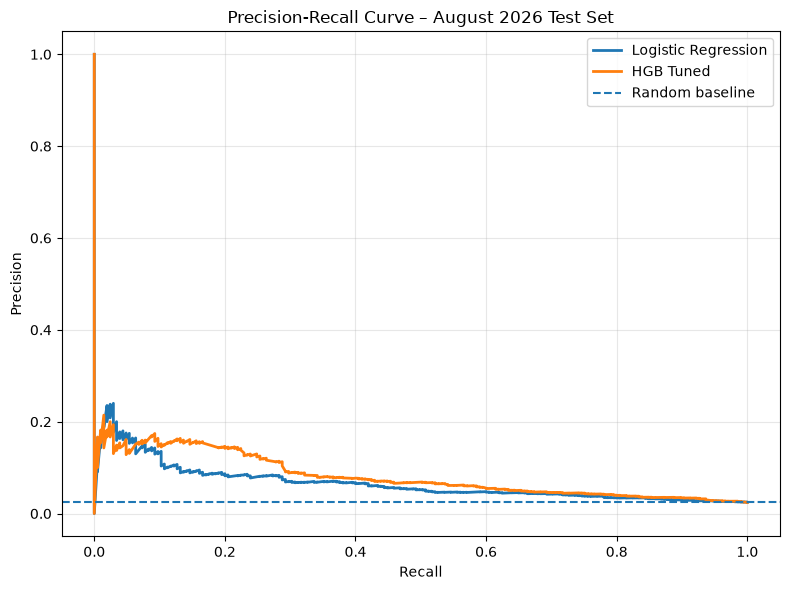

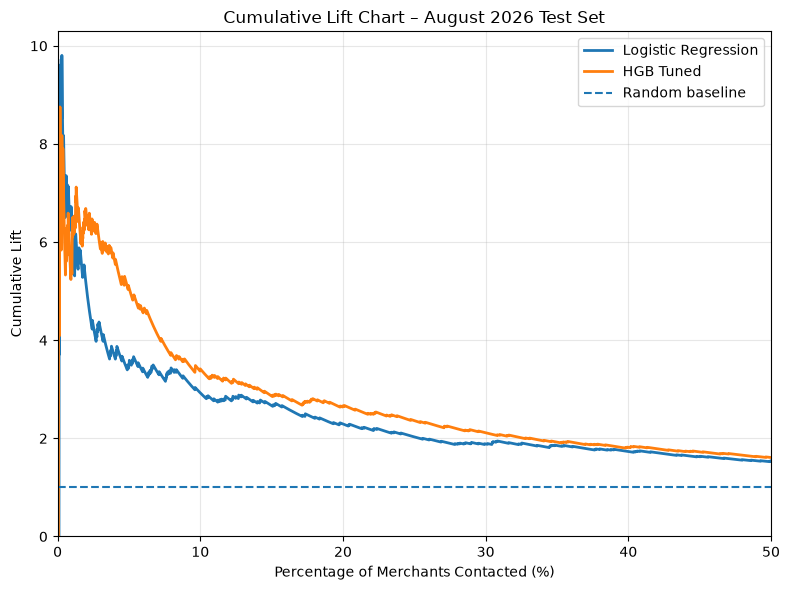

In [ ]:
from sklearn.metrics import precision_recall_curve

model_probabilities = {
    "Logistic Regression": logistic_test_prob,
    "HGB Tuned": y_test_prob
}

# Chart 1: Precision-Recall Curve
plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=model_name,
        linewidth=2
    )

# Random baseline: test-set churn prevalence
plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – August 2026 Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Cumulative Lift Chart
plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():
    sorted_indices = np.argsort(probabilities)[::-1]
    sorted_y = np.asarray(y_test)[sorted_indices]

    cumulative_churn = np.cumsum(sorted_y)
    merchants_contacted = np.arange(1, len(sorted_y) + 1)

    cumulative_precision = (
        cumulative_churn / merchants_contacted
    )

    cumulative_lift = cumulative_precision / y_test.mean()

    contact_percentage = (
        merchants_contacted / len(sorted_y) * 100
    )

    plt.plot(
        contact_percentage,
        cumulative_lift,
        label=model_name,
        linewidth=2
    )

# Random selection baseline
plt.axhline(
    y=1,
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("Percentage of Merchants Contacted (%)")
plt.ylabel("Cumulative Lift")
plt.title("Cumulative Lift Chart – August 2026 Test Set")
plt.xlim(0, 50)
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2. Model Interpretation

#### 2.1. Permutation Feature Importance

In [ ]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
}).sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

display(permutation_importance_df.head(15).round(5))

,Feature,Importance Mean,Importance Std
0,searches_growth_60d,0.02439,0.00410
1,searches_growth_30d,0.01490,0.00405
2,gmv_growth_30d,0.00901,0.00400
3,bom_mrr,0.00479,0.00146
4,tenure_months,0.00293,0.00221
5,product_clicks_growth_30d,0.00292,0.00168
6,searches_60d,0.00274,0.00079
7,gmv_60d,0.00227,0.00079
8,gmv_growth_60d,0.00202,0.00165
9,mrr_change,0.00201,0.00059


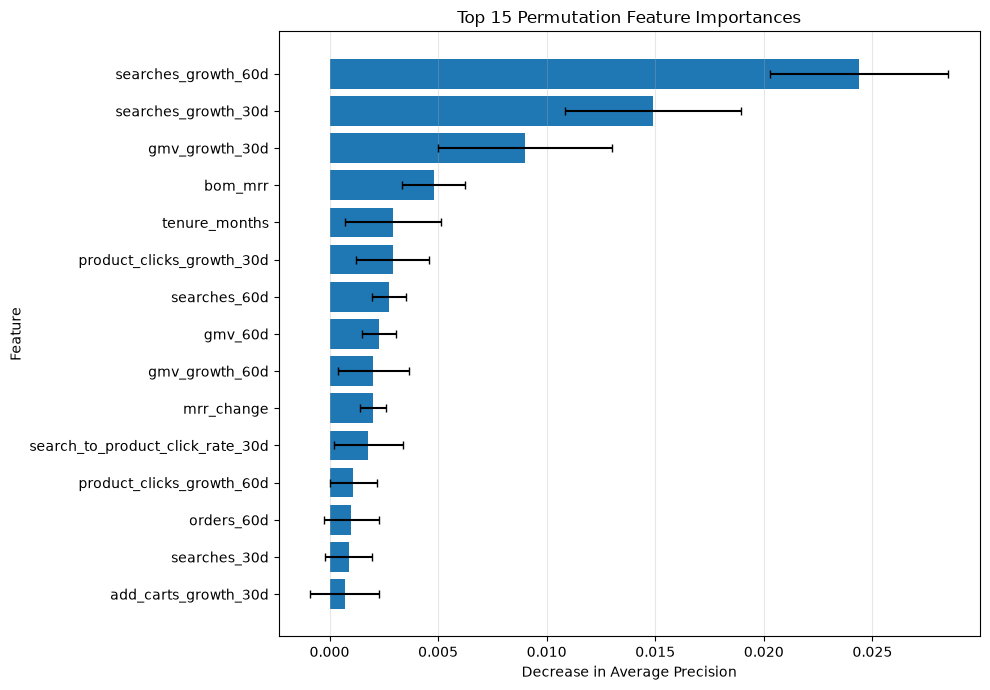

In [ ]:
top_features = permutation_importance_df.head(15).sort_values(
    "Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"],
    capsize=3
)

plt.xlabel("Decrease in Average Precision")
plt.ylabel("Feature")
plt.title("Top 15 Permutation Feature Importances")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### 2.2. SHAP Analysis

In [ ]:
# Select SHAP values for churn class (class 1)
shap_values_churn = shap_values.values[:, :, 1]

# Retrieve transformed feature names
transformed_names = fitted_preprocessor.get_feature_names_out()

# Map transformed features to their original features
original_feature_names = []

for transformed_name in transformed_names:
    original_name = transformed_name.split("__", 1)[-1]

    # Handle One-Hot Encoded categorical features
    if transformed_name.startswith("categorical__"):
        for categorical_feature in categorical_features:
            if original_name.startswith(categorical_feature + "_"):
                original_name = categorical_feature
                break

    # Handle missing indicators
    if transformed_name.startswith("missing_indicators__"):
        original_name = transformed_name.replace(
            "missing_indicators__",
            ""
        )

    original_feature_names.append(original_name)

# Aggregate SHAP contributions by original feature
shap_by_original_feature = {}

for i, original_name in enumerate(original_feature_names):
    if original_name not in shap_by_original_feature:
        shap_by_original_feature[original_name] = []

    shap_by_original_feature[original_name].append(
        shap_values_churn[:, i]
    )

aggregated_shap_values = {
    feature: np.sum(np.column_stack(values), axis=1)
    for feature, values in shap_by_original_feature.items()
}

# Calculate mean absolute SHAP values
shap_importance_df = pd.DataFrame({
    "Feature": list(aggregated_shap_values.keys()),
    "Mean Absolute SHAP": [
        np.abs(values).mean()
        for values in aggregated_shap_values.values()
    ]
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

print("Original features represented:", len(shap_importance_df))
display(shap_importance_df.head(15).round(5))

Original features represented: 79


,Feature,Mean Absolute SHAP
0,searches_growth_60d,0.00499
1,gmv_growth_30d,0.00274
2,missingindicator_searches_growth_60d,0.00243
3,tenure_months,0.00243
4,searches_growth_30d,0.00235
5,add_carts_growth_30d,0.00142
6,eom_mrr,0.00133
7,product_clicks_growth_30d,0.00114
8,product_clicks_growth_60d,0.00113
9,missingindicator_searches_60d,0.00095


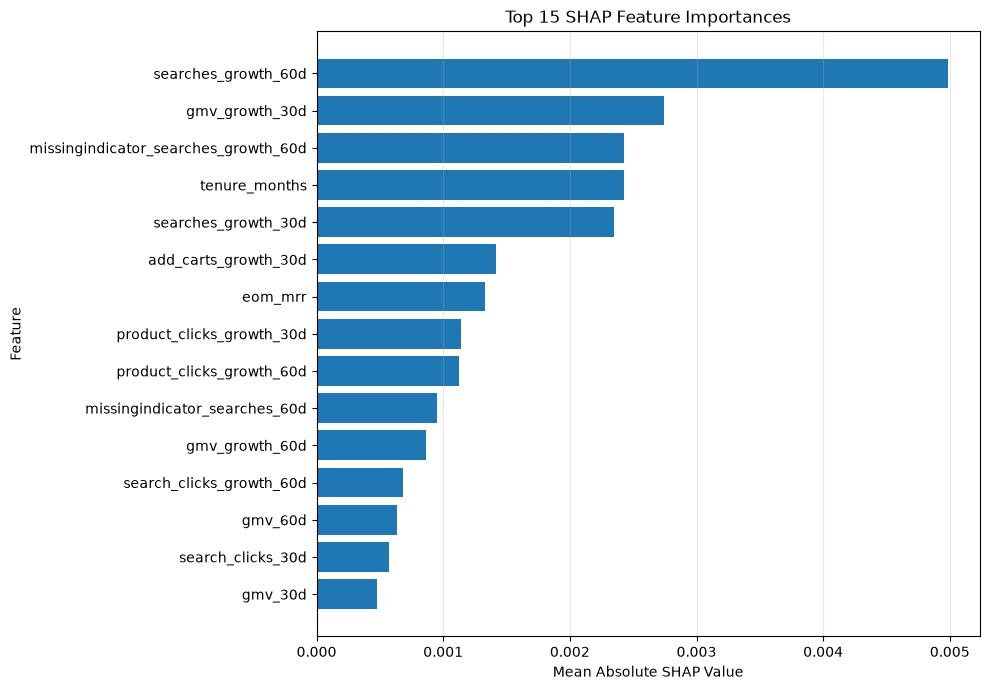

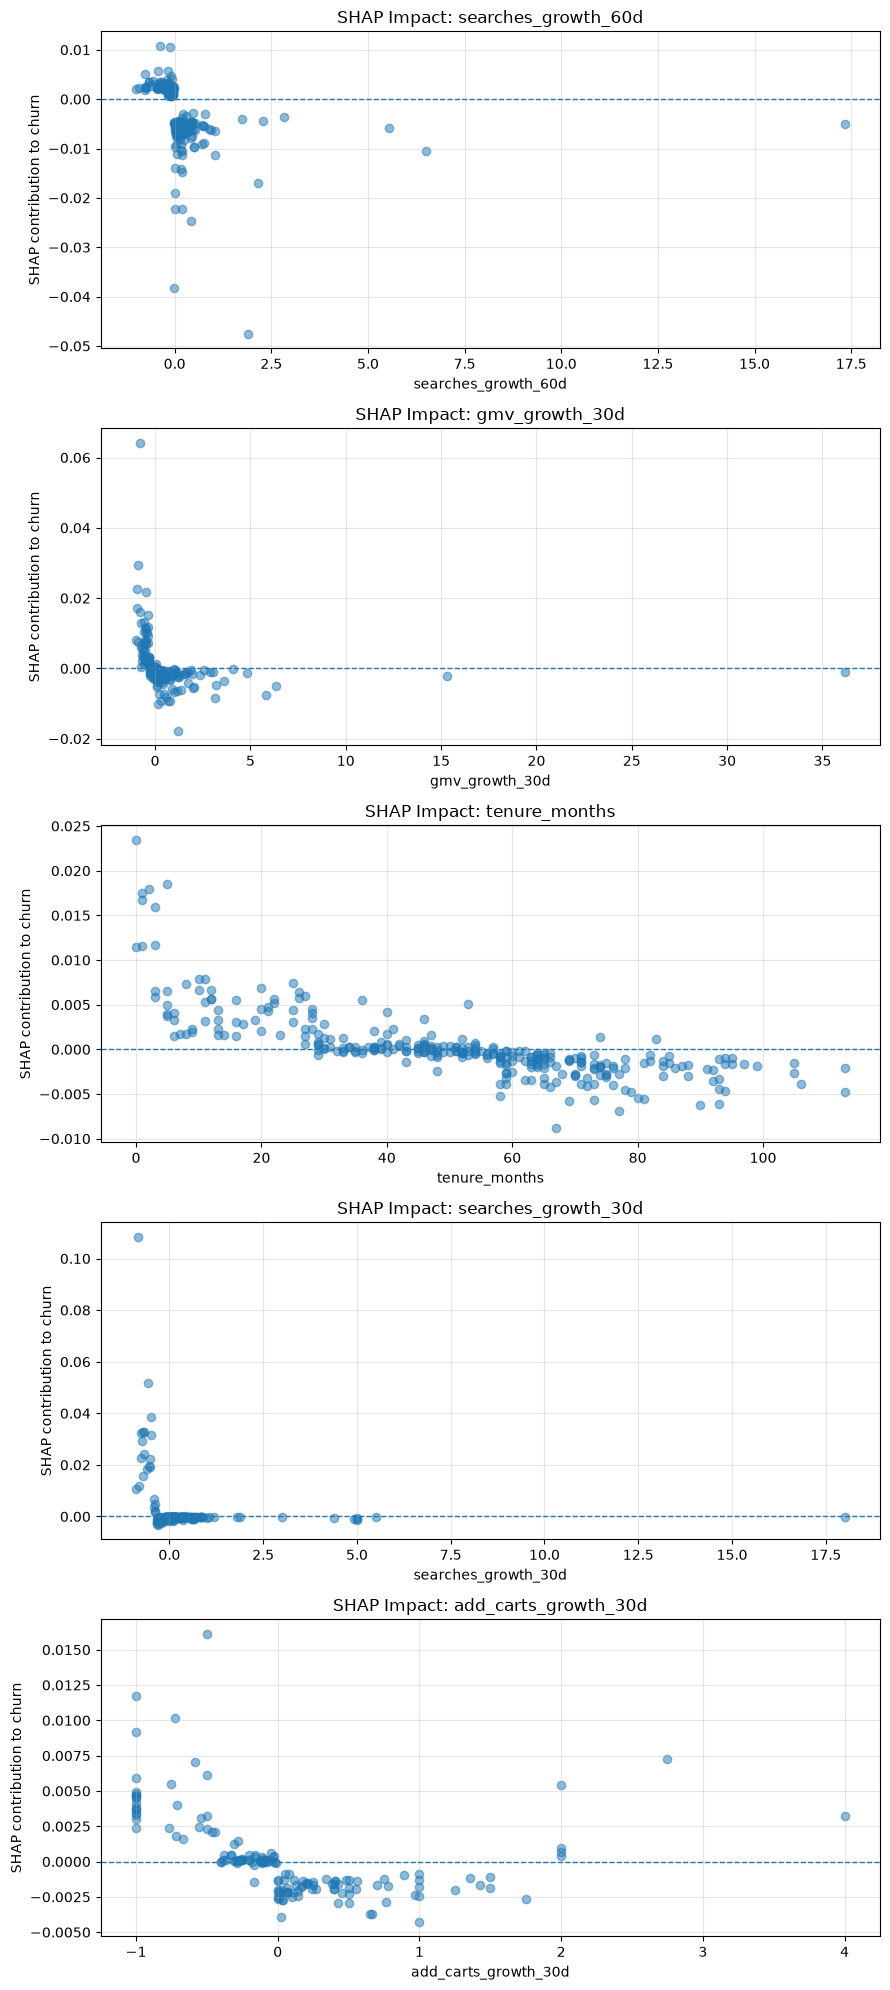

In [ ]:
# 1. Global SHAP importance: original feature level
top_shap = shap_importance_df.head(15).sort_values(
    "Mean Absolute SHAP",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_shap["Feature"],
    top_shap["Mean Absolute SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 SHAP Feature Importances")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Explore impact direction for top original numeric features
features_to_interpret = [
    "searches_growth_60d",
    "gmv_growth_30d",
    "tenure_months",
    "searches_growth_30d",
    "add_carts_growth_30d"
]

fig, axes = plt.subplots(
    nrows=len(features_to_interpret),
    ncols=1,
    figsize=(9, 4 * len(features_to_interpret))
)

for ax, feature in zip(axes, features_to_interpret):
    feature_values = X_shap[feature].to_numpy()
    feature_shap_values = aggregated_shap_values[feature]

    valid_mask = (
        pd.notna(feature_values)
        & np.isfinite(feature_shap_values)
    )

    ax.scatter(
        feature_values[valid_mask],
        feature_shap_values[valid_mask],
        alpha=0.5
    )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xlabel(feature)
    ax.set_ylabel("SHAP contribution to churn")
    ax.set_title(f"SHAP Impact: {feature}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 3.3.6 Analyze SHAP impact direction by feature value

features_to_interpret = [
    "searches_growth_60d",
    "gmv_growth_30d",
    "tenure_months",
    "searches_growth_30d",
    "add_carts_growth_30d"
]

direction_results = []

for feature in features_to_interpret:
    values = X_shap[feature]
    shap_contributions = aggregated_shap_values[feature]

    analysis_df = pd.DataFrame({
        "feature_value": values,
        "shap_value": shap_contributions
    }).dropna()

    # Compare lower and upper quartiles
    q25 = analysis_df["feature_value"].quantile(0.25)
    q75 = analysis_df["feature_value"].quantile(0.75)

    low_group = analysis_df[
        analysis_df["feature_value"] <= q25
    ]

    high_group = analysis_df[
        analysis_df["feature_value"] >= q75
    ]

    direction_results.append({
        "Feature": feature,
        "Low Value Range": f"<= {q25:.3f}",
        "Low Mean SHAP": low_group["shap_value"].mean(),
        "High Value Range": f">= {q75:.3f}",
        "High Mean SHAP": high_group["shap_value"].mean(),
        "Spearman Correlation": analysis_df[
            ["feature_value", "shap_value"]
        ].corr(method="spearman").iloc[0, 1]
    })

direction_summary = pd.DataFrame(direction_results)

display(
    direction_summary.style.format({
        "Low Mean SHAP": "{:.5f}",
        "High Mean SHAP": "{:.5f}",
        "Spearman Correlation": "{:.3f}"
    })
)

,Feature,Low Value Range,Low Mean SHAP,High Value Range,High Mean SHAP,Spearman Correlation
0,searches_growth_60d,<= -0.149,0.00279,>= 0.197,-0.00741,-0.781
1,gmv_growth_30d,<= -0.228,0.00678,>= 0.343,-0.00311,-0.789
2,tenure_months,<= 32.750,0.00498,>= 68.250,-0.00251,-0.877
3,searches_growth_30d,<= -0.160,0.00931,>= 0.289,-0.00040,0.061
4,add_carts_growth_30d,<= -0.300,0.00376,>= 0.390,-0.00123,-0.698


#### 2.3. Business Interpretation of Key Features

### 3. Error Analysis

In [ ]:
FINAL_THRESHOLD = 0.04

test_results = X_test.copy()

test_results["actual_churn"] = y_test.values
test_results["churn_probability"] = y_test_prob
test_results["predicted_churn"] = (
    test_results["churn_probability"] >= FINAL_THRESHOLD
).astype(int)

# Classify prediction outcomes
test_results["prediction_result"] = np.select(
    [
        (test_results["actual_churn"] == 1) &
        (test_results["predicted_churn"] == 1),

        (test_results["actual_churn"] == 0) &
        (test_results["predicted_churn"] == 1),

        (test_results["actual_churn"] == 1) &
        (test_results["predicted_churn"] == 0),

        (test_results["actual_churn"] == 0) &
        (test_results["predicted_churn"] == 0)
    ],
    [
        "True Positive",
        "False Positive",
        "False Negative",
        "True Negative"
    ],
    default="Unclassified"
)

error_summary = (
    test_results["prediction_result"]
    .value_counts()
    .reindex(
        ["True Positive", "False Positive", "False Negative", "True Negative"],
        fill_value=0
    )
    .rename_axis("Prediction Result")
    .reset_index(name="Merchant Count")
)

display(error_summary)

,Prediction Result,Merchant Count
0,True Positive,85
1,False Positive,1050
2,False Negative,120
3,True Negative,7120


#### 3.1. False Negative and False Positive Analysis

In [ ]:
features_to_compare = [
    "tenure_months",
    "eom_mrr",
    "bom_mrr",
    "gmv_30d",
    "gmv_growth_30d",
    "searches_30d",
    "searches_growth_60d",
    "orders_30d",
    "has_gmv_data",
    "has_search_data"
]

error_group_summary = (
    test_results
    .groupby("prediction_result")[features_to_compare]
    .median()
    .T
)

display(error_group_summary)

prediction_result,False Negative,False Positive,True Negative,True Positive
tenure_months,57.500000,28.500000,57.000000,21.000000
eom_mrr,34.000000,29.000000,29.000000,29.000000
bom_mrr,29.000000,29.000000,29.000000,29.000000
gmv_30d,39787.407452,14646.339288,34699.406345,11838.364885
gmv_growth_30d,0.030844,-0.317767,0.040099,-0.379914
searches_30d,1119.000000,96.500000,2232.000000,131.000000
searches_growth_60d,-0.029694,-0.305925,0.046166,-0.266551
orders_30d,1.000000,0.000000,2.000000,0.000000
has_gmv_data,1.000000,1.000000,1.000000,1.000000
has_search_data,1.000000,0.000000,1.000000,0.000000


In [ ]:
availability_summary = (
    test_results
    .groupby("prediction_result")
    .agg(
        merchant_count=("actual_churn", "size"),
        gmv_data_rate=("has_gmv_data", "mean"),
        search_data_rate=("has_search_data", "mean")
    )
    .reset_index()
)

availability_summary["gmv_data_rate"] *= 100
availability_summary["search_data_rate"] *= 100

display(
    availability_summary.style.format({
        "gmv_data_rate": "{:.2f}%",
        "search_data_rate": "{:.2f}%"
    })
)

,prediction_result,merchant_count,gmv_data_rate,search_data_rate
0,False Negative,120,85.83%,62.50%
1,False Positive,1050,57.24%,36.57%
2,True Negative,7120,90.80%,79.21%
3,True Positive,85,64.71%,43.53%


**Error Analysis – Key Findings**

1. **False Negatives:** These merchants tend to have longer tenure and higher GMV and search activity than correctly identified churned merchants. Their business activity may not show the typical decline patterns learned by the model, making them harder to identify.

2. **False Positives:** These merchants generally show weaker business activity and higher data missingness than true negatives. Although they did not churn in the test period, their declining activity may still justify proactive monitoring.

Overall, the model is more effective at identifying merchants with visible signs of declining activity. However, it may overlook established merchants who churn without substantial preceding declines, while overestimating risk for merchants with limited activity data.

### 4. September Merchant Scoring

#### 4.0. Create tables for Septem scoring

In [ ]:
scoring_sql = (
    PROJECT_ROOT / "scripts" / "scoring" / "scoring_features.sql"
).read_text(encoding="utf-8")

con = duckdb.connect(
    str(PROJECT_ROOT / "data" / "boost_churn.duckdb")
)

# Execute scoring feature SQL
con.execute(scoring_sql)

# Validate row counts and duplicates
scoring_feature_check = con.execute("""
    SELECT
        'GMV' AS feature_type,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT shop_key) AS unique_merchants,
        COUNT(*) FILTER (
            WHERE snapshot_month = DATE '2026-09-01'
        ) AS september_rows
    FROM staging.stg_gmv_features_score_202609

    UNION ALL

    SELECT
        'Search' AS feature_type,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT shop_key) AS unique_merchants,
        COUNT(*) FILTER (
            WHERE snapshot_month = DATE '2026-09-01'
        ) AS september_rows
    FROM staging.stg_search_features_score_202609
""").df()

display(scoring_feature_check)

con.close()

,feature_type,total_rows,unique_merchants,september_rows
0,GMV,8227,8227,8227
1,Search,8227,8227,8227


In [ ]:
scoring_set_sql = """
CREATE OR REPLACE TABLE mart.churn_scoring_set_2026_09 AS

WITH finance_features AS (
    SELECT
        shop_key,
        snapshot_month,
        tenure_months,
        bom_mrr,
        eom_mrr,
        eom_mrr - bom_mrr AS mrr_change,

        CASE
            WHEN bom_mrr > 0
            THEN (eom_mrr - bom_mrr) / bom_mrr
            ELSE NULL
        END AS mrr_growth_rate,

        CASE
            WHEN bom_mrr = 0 AND eom_mrr > 0 THEN 'new_mrr'
            WHEN eom_mrr > bom_mrr THEN 'increased'
            WHEN eom_mrr = bom_mrr THEN 'unchanged'
            WHEN eom_mrr < bom_mrr THEN 'decreased'
            ELSE NULL
        END AS mrr_movement_type,

        has_search_data,
        total_searches AS searches_30d,
        total_product_click AS product_clicks_30d,
        total_search_click AS search_clicks_30d,
        total_add_carts AS add_carts_30d,
        total_orders AS orders_30d,

        NULL::INTEGER AS churn_next_30d

    FROM mart.fact_merchant_monthly
    WHERE snapshot_month = DATE '2026-09-01'
      AND eom_mrr > 0
      AND churn_mrr = 0
),

scoring_features AS (
    SELECT
        f.*,

        g.gmv_30d,
        g.gmv_60d,
        g.gmv_growth_30d,
        g.gmv_growth_60d,
        g.gmv_currency_code,
        g.has_gmv_data,
        g.multi_currency_flag,

        s.searches_60d,
        s.product_clicks_60d,
        s.search_clicks_60d,
        s.add_carts_60d,
        s.orders_60d,

        s.searches_growth_30d,
        s.product_clicks_growth_30d,
        s.search_clicks_growth_30d,
        s.add_carts_growth_30d,
        s.orders_growth_30d,

        s.searches_growth_60d,
        s.product_clicks_growth_60d,
        s.search_clicks_growth_60d,
        s.add_carts_growth_60d,
        s.orders_growth_60d,

        s.search_to_product_click_rate_30d,
        s.search_click_rate_30d,
        s.product_click_to_cart_rate_30d,
        s.cart_to_order_rate_30d,

        s.search_to_product_click_rate_60d,
        s.search_click_rate_60d,
        s.product_click_to_cart_rate_60d,
        s.cart_to_order_rate_60d

    FROM finance_features f

    LEFT JOIN staging.stg_gmv_features_score_202609 g
        ON f.shop_key = g.shop_key
       AND f.snapshot_month = g.snapshot_month

    LEFT JOIN staging.stg_search_features_score_202609 s
        ON f.shop_key = s.shop_key
       AND f.snapshot_month = s.snapshot_month
)

SELECT
    *,
    'score' AS split
FROM scoring_features;
"""

# Save the SQL script
scoring_path = PROJECT_ROOT / "scripts" / "scoring" / "scoring_set.sql"
scoring_path.write_text(scoring_set_sql, encoding="utf-8")

# Execute
con = duckdb.connect(
    str(PROJECT_ROOT / "data" / "boost_churn.duckdb")
)

con.execute(scoring_set_sql)

# Validate scoring dataset
scoring_check = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT shop_key) AS unique_merchants,
        COUNT(*) FILTER (
            WHERE churn_next_30d IS NULL
        ) AS null_labels,
        COUNT(*) FILTER (
            WHERE split = 'score'
        ) AS score_rows,
        COUNT(*) FILTER (
            WHERE eom_mrr <= 0
        ) AS invalid_mrr_rows
    FROM mart.churn_scoring_set_2026_09
""").df()

# Compare column names and order with training set
training_columns = con.execute("""
    PRAGMA table_info('mart.churn_training_set')
""").df()["name"].tolist()

scoring_columns = con.execute("""
    PRAGMA table_info('mart.churn_scoring_set_2026_09')
""").df()["name"].tolist()

print("Scoring validation:")
display(scoring_check)

print("Training columns:", len(training_columns))
print("Scoring columns:", len(scoring_columns))
print("Same column names and order:", training_columns == scoring_columns)
print("SQL saved at:", scoring_path)

con.close()

Scoring validation:


,total_rows,unique_merchants,null_labels,score_rows,invalid_mrr_rows
0,8227,8227,8227,8227,0


Training columns: 46
Scoring columns: 46
Same column names and order: True
SQL saved at: d:\DAC\CHURN_PREDICTION\scripts\scoring\scoring_set.sql


In [ ]:
# Data quality check
con = duckdb.connect(str(PROJECT_ROOT / "data" / "boost_churn.duckdb"), read_only=True)

training_info = con.execute(
    "PRAGMA table_info('mart.churn_training_set')"
).df()

scoring_info = con.execute(
    "PRAGMA table_info('mart.churn_scoring_set_2026_09')"
).df()

type_comparison = training_info[["name", "type"]].merge(
    scoring_info[["name", "type"]],
    on="name",
    suffixes=("_training", "_scoring")
)

mismatches = type_comparison[
    type_comparison["type_training"] != type_comparison["type_scoring"]
]

print("Number of columns with different data types:", len(mismatches))
display(mismatches)

con.close()

Number of columns with different data types: 0


,name,type_training,type_scoring


In [ ]:
import joblib
import json

MODEL_PATH = PROJECT_ROOT / "models" / "final_churn_model.pkl"
METADATA_PATH = PROJECT_ROOT / "models" / "final_churn_model_metadata.json"

final_model = joblib.load(MODEL_PATH)

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

print("Model loaded:", type(final_model).__name__)
print("\nModel metadata:")
print(json.dumps(model_metadata, indent=2, ensure_ascii=False))

Model loaded: Pipeline

Model metadata:
{
  "model_name": "HistGradientBoosting Tuned",
  "training_period": [
    "2026-06",
    "2026-07"
  ],
  "test_period": "2026-08",
  "target": "churn_next_30d",
  "threshold": 0.04,
  "features": [
    "tenure_months",
    "bom_mrr",
    "eom_mrr",
    "mrr_change",
    "mrr_growth_rate",
    "mrr_movement_type",
    "has_search_data",
    "searches_30d",
    "product_clicks_30d",
    "search_clicks_30d",
    "add_carts_30d",
    "orders_30d",
    "gmv_30d",
    "gmv_60d",
    "gmv_growth_30d",
    "gmv_growth_60d",
    "gmv_currency_code",
    "has_gmv_data",
    "multi_currency_flag",
    "searches_60d",
    "product_clicks_60d",
    "search_clicks_60d",
    "add_carts_60d",
    "orders_60d",
    "searches_growth_30d",
    "product_clicks_growth_30d",
    "search_clicks_growth_30d",
    "add_carts_growth_30d",
    "orders_growth_30d",
    "searches_growth_60d",
    "product_clicks_growth_60d",
    "search_clicks_growth_60d",
    "add_carts_gr

In [ ]:
# September Feature matrix
con = duckdb.connect(str(PROJECT_ROOT / "data" / "boost_churn.duckdb"), read_only=True)

score_df = con.execute("""
    SELECT *
    FROM mart.churn_scoring_set_2026_09
""").df()

con.close()

# Lấy đúng danh sách features từ metadata
feature_columns = model_metadata["features"]

# Kiểm tra feature mapping
missing_features = [
    col for col in feature_columns
    if col not in score_df.columns
]

print("Scoring dataset shape:", score_df.shape)
print("Number of model features:", len(feature_columns))
print("Missing features:", missing_features)

# Chỉ tạo feature matrix khi tất cả features đều tồn tại
if not missing_features:
    X_score = score_df[feature_columns].copy()
    print("Feature matrix shape:", X_score.shape)
    print("Feature order matches metadata:", X_score.columns.tolist() == feature_columns)

Scoring dataset shape: (8227, 46)
Number of model features: 42
Missing features: []
Feature matrix shape: (8227, 42)
Feature order matches metadata: True


#### 4.1. Generate Churn Probabilities

In [ ]:
# Predict probability of churn (class 1)
churn_probabilities = final_model.predict_proba(X_score)[:, 1]

# Scroing result
scoring_results = score_df[
    ["shop_key", "snapshot_month", "eom_mrr"]
].copy()

scoring_results["churn_probability"] = churn_probabilities

# Sort by churn probability
scoring_results = scoring_results.sort_values(
    "churn_probability",
    ascending=False
).reset_index(drop=True)

scoring_results["rank"] = range(1, len(scoring_results) + 1)

# Reorder columns
scoring_results = scoring_results[
    [
        "shop_key",
        "churn_probability",
        "rank",
        "eom_mrr"
    ]
]

print("Total scored merchants:", len(scoring_results))
print("\nChurn probability summary:")
display(scoring_results["churn_probability"].describe())

print("\nTop 10 merchants at risk:")
display(scoring_results.head(10))

Total scored merchants: 8227

Churn probability summary:


count    8227.000000
mean        0.084992
std         0.071666
min         0.010451
25%         0.036498
50%         0.058169
75%         0.112773
max         0.639599
Name: churn_probability, dtype: float64


Top 10 merchants at risk:


,shop_key,churn_probability,rank,eom_mrr
0,store-12wh0jb3.myshopify.com,0.639599,1,329.0
1,store-8i4ola4d.myshopify.com,0.607707,2,449.0
2,store-dbbv8ho5.myshopify.com,0.592657,3,449.0
3,store-5w142ygc.myshopify.com,0.545465,4,69.0
4,store-wevzof8w.myshopify.com,0.529915,5,79.0
5,store-q1rcc9r0.myshopify.com,0.504955,6,69.0
6,store-l0s95eqk.myshopify.com,0.502626,7,79.0
7,store-48igsgxp.myshopify.com,0.499905,8,69.0
8,store-39cdwrsk.myshopify.com,0.493210,9,129.0
9,store-565ra5mu.myshopify.com,0.486451,10,69.0


#### 4.2. Rank Merchants by Churn Risk

In [ ]:
threshold = model_metadata["threshold"]

total_merchants = len(scoring_results)

high_risk = scoring_results[
    scoring_results["churn_probability"] >= threshold
]

print(f"Model threshold: {threshold:.0%}")
print(f"High-risk merchants: {len(high_risk):,}")
print(f"High-risk percentage: {len(high_risk) / total_merchants:.2%}")

for pct in [0.05, 0.10]:
    top_n = int(np.ceil(total_merchants * pct))
    top_group = scoring_results.head(top_n)

    print(f"\nTop {pct:.0%} ({top_n:,} merchants)")
    print(f"Average churn probability: {top_group['churn_probability'].mean():.2%}")
    print(f"Median churn probability: {top_group['churn_probability'].median():.2%}")
    print(f"Total EOM MRR: {top_group['eom_mrr'].sum():,.2f}")

Model threshold: 4%
High-risk merchants: 5,783
High-risk percentage: 70.29%

Top 5% (412 merchants)
Average churn probability: 30.72%
Median churn probability: 28.40%
Total EOM MRR: 66,107.50

Top 10% (823 merchants)
Average churn probability: 25.30%
Median churn probability: 23.05%
Total EOM MRR: 118,661.68


In [ ]:
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ranking_path = OUTPUT_DIR / "merchant_churn_ranking_2026_09.csv"

scoring_results.to_csv(ranking_path, index=False)

print("Ranking file saved:", ranking_path)
print("Total merchants ranked:", len(scoring_results))
print("\nTop 5 merchants:")
display(scoring_results.head())

Ranking file saved: d:\DAC\CHURN_PREDICTION\outputs\merchant_churn_ranking_2026_09.csv
Total merchants ranked: 8227

Top 5 merchants:


,shop_key,churn_probability,rank,eom_mrr
0,store-12wh0jb3.myshopify.com,0.639599,1,329.0
1,store-8i4ola4d.myshopify.com,0.607707,2,449.0
2,store-dbbv8ho5.myshopify.com,0.592657,3,449.0
3,store-5w142ygc.myshopify.com,0.545465,4,69.0
4,store-wevzof8w.myshopify.com,0.529915,5,79.0


#### 4.3. Estimate MRR at Risk

In [ ]:
scoring_results["expected_mrr_at_risk"] = (
    scoring_results["churn_probability"] * scoring_results["eom_mrr"]
)

print("Total current EOM MRR:",
      f"{scoring_results['eom_mrr'].sum():,.2f}")

print("Total Expected MRR at Risk:",
      f"{scoring_results['expected_mrr_at_risk'].sum():,.2f}")

print("\nExpected MRR at Risk summary:")
display(scoring_results["expected_mrr_at_risk"].describe())

Total current EOM MRR: 688,737.89
Total Expected MRR at Risk: 77,329.49

Expected MRR at Risk summary:


count    8227.000000
mean        9.399476
std        24.644721
min         0.003790
25%         0.897466
50%         2.356890
75%         7.750887
max       760.730968
Name: expected_mrr_at_risk, dtype: float64

In [ ]:
# Rank merchants by expected MRR at Risk
mrr_risk_results = scoring_results.sort_values(
    "expected_mrr_at_risk",
    ascending=False
).reset_index(drop=True)

total_mrr_at_risk = mrr_risk_results["expected_mrr_at_risk"].sum()

print("MRR at Risk concentration by merchant group:")

for pct in [0.05, 0.10, 0.20]:
    top_n = int(np.ceil(len(mrr_risk_results) * pct))
    top_group = mrr_risk_results.head(top_n)

    group_mrr_at_risk = top_group["expected_mrr_at_risk"].sum()

    print(f"\nTop {pct:.0%} ({top_n:,} merchants)")
    print(f"Expected MRR at Risk: {group_mrr_at_risk:,.2f}")
    print(f"Share of total MRR at Risk: {group_mrr_at_risk / total_mrr_at_risk:.2%}")
    print(f"Current EOM MRR: {top_group['eom_mrr'].sum():,.2f}")

print("\nTop 10 merchants by Expected MRR at Risk:")
display(
    mrr_risk_results[
        ["shop_key", "churn_probability", "eom_mrr", "expected_mrr_at_risk"]
    ].head(10)
)

MRR at Risk concentration by merchant group:

Top 5% (412 merchants)
Expected MRR at Risk: 35,437.31
Share of total MRR at Risk: 45.83%
Current EOM MRR: 202,668.89

Top 10% (823 merchants)
Expected MRR at Risk: 47,657.80
Share of total MRR at Risk: 61.63%
Current EOM MRR: 300,094.62

Top 20% (1,646 merchants)
Expected MRR at Risk: 60,386.17
Share of total MRR at Risk: 78.09%
Current EOM MRR: 418,891.09

Top 10 merchants by Expected MRR at Risk:


,shop_key,churn_probability,eom_mrr,expected_mrr_at_risk
0,store-0k94ar09.myshopify.com,0.370483,2053.35,760.730968
1,store-q6bdbw8f.myshopify.com,0.392458,1199.40,470.713603
2,store-0fuaed5w.myshopify.com,0.306829,1499.00,459.937033
3,store-alhqb8k7.myshopify.com,0.350491,1199.40,420.378766
4,store-njas5vbe.myshopify.com,0.261396,1274.15,333.057784
5,store-9mbczuio.myshopify.com,0.472196,639.20,301.827894
6,store-1iig9ced.myshopify.com,0.419936,699.00,293.535012
7,store-ghryfxwg.myshopify.com,0.463868,629.00,291.773123
8,store-a2q54knx.myshopify.com,0.141074,2049.00,289.059769
9,store-8i4ola4d.myshopify.com,0.607707,449.00,272.860240


In [ ]:
# Add a second ranking based on expected MRR at Risk
scoring_results["mrr_risk_rank"] = (
    scoring_results["expected_mrr_at_risk"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Arrange final output columns
final_scoring_results = scoring_results[
    [
        "shop_key",
        "churn_probability",
        "rank",
        "eom_mrr",
        "expected_mrr_at_risk",
        "mrr_risk_rank"
    ]
].copy()

# Overwrite the existing ranking file with the complete results
ranking_path = OUTPUT_DIR / "merchant_churn_ranking_2026_09.csv"

final_scoring_results.to_csv(ranking_path, index=False)

print("Final scoring output saved:", ranking_path)
print("Total merchants:", len(final_scoring_results))
print("Total expected MRR at Risk:",
      f"{final_scoring_results['expected_mrr_at_risk'].sum():,.2f}")

display(final_scoring_results.head(10))

Final scoring output saved: d:\DAC\CHURN_PREDICTION\outputs\merchant_churn_ranking_2026_09.csv
Total merchants: 8227
Total expected MRR at Risk: 77,329.49


,shop_key,churn_probability,rank,eom_mrr,expected_mrr_at_risk,mrr_risk_rank
0,store-12wh0jb3.myshopify.com,0.639599,1,329.0,210.428029,23
1,store-8i4ola4d.myshopify.com,0.607707,2,449.0,272.860240,10
2,store-dbbv8ho5.myshopify.com,0.592657,3,449.0,266.102981,12
3,store-5w142ygc.myshopify.com,0.545465,4,69.0,37.637105,435
4,store-wevzof8w.myshopify.com,0.529915,5,79.0,41.863294,366
5,store-q1rcc9r0.myshopify.com,0.504955,6,69.0,34.841921,486
6,store-l0s95eqk.myshopify.com,0.502626,7,79.0,39.707475,406
7,store-48igsgxp.myshopify.com,0.499905,8,69.0,34.493425,490
8,store-39cdwrsk.myshopify.com,0.493210,9,129.0,63.624119,199
9,store-565ra5mu.myshopify.com,0.486451,10,69.0,33.565089,509


#### 4.4. Export At-Risk Merchant List

In [ ]:
# Filter merchants exceeding the selected churn threshold
at_risk_merchants = final_scoring_results[
    final_scoring_results["churn_probability"] >= threshold
].copy()

# Assign priority based on financial risk ranking
at_risk_merchants["priority"] = np.select(
    [
        at_risk_merchants["mrr_risk_rank"] <= int(np.ceil(len(final_scoring_results) * 0.05)),
        at_risk_merchants["mrr_risk_rank"] <= int(np.ceil(len(final_scoring_results) * 0.10))
    ],
    [
        "High",
        "Medium"
    ],
    default="Monitor"
)

print("Total at-risk merchants:", len(at_risk_merchants))

print("\nPriority distribution:")
display(at_risk_merchants["priority"].value_counts())

print("\nAt-risk merchant list:")
display(at_risk_merchants.head(10))

Total at-risk merchants: 5783

Priority distribution:


priority
Monitor    4966
High        410
Medium      407
Name: count, dtype: int64


At-risk merchant list:


,shop_key,churn_probability,rank,eom_mrr,expected_mrr_at_risk,mrr_risk_rank,priority
0,store-12wh0jb3.myshopify.com,0.639599,1,329.0,210.428029,23,High
1,store-8i4ola4d.myshopify.com,0.607707,2,449.0,272.860240,10,High
2,store-dbbv8ho5.myshopify.com,0.592657,3,449.0,266.102981,12,High
3,store-5w142ygc.myshopify.com,0.545465,4,69.0,37.637105,435,Medium
4,store-wevzof8w.myshopify.com,0.529915,5,79.0,41.863294,366,High
5,store-q1rcc9r0.myshopify.com,0.504955,6,69.0,34.841921,486,Medium
6,store-l0s95eqk.myshopify.com,0.502626,7,79.0,39.707475,406,High
7,store-48igsgxp.myshopify.com,0.499905,8,69.0,34.493425,490,Medium
8,store-39cdwrsk.myshopify.com,0.493210,9,129.0,63.624119,199,High
9,store-565ra5mu.myshopify.com,0.486451,10,69.0,33.565089,509,Medium


In [ ]:
at_risk_path = OUTPUT_DIR / "at_risk_merchants_2026_09.csv"

at_risk_merchants.to_csv(at_risk_path, index=False)

print("At-risk merchant list saved:", at_risk_path)
print("Total at-risk merchants:", len(at_risk_merchants))
print("\nPriority distribution:")
display(
    at_risk_merchants.groupby("priority").agg(
        merchant_count=("shop_key", "count"),
        total_eom_mrr=("eom_mrr", "sum"),
        total_expected_mrr_at_risk=("expected_mrr_at_risk", "sum")
    ).sort_values("total_expected_mrr_at_risk", ascending=False)
)

At-risk merchant list saved: d:\DAC\CHURN_PREDICTION\outputs\at_risk_merchants_2026_09.csv
Total at-risk merchants: 5783

Priority distribution:


,merchant_count,total_eom_mrr,total_expected_mrr_at_risk
priority,,,
High,410,199642.694333,35323.587010
Monitor,4966,284871.592625,26581.741889
Medium,407,93949.628100,12109.800839


## E. Business Recommendations

### 1. Segmentation

In [ ]:
# Retrieve clustering thresholds from the data
print("EOM MRR quantiles:")
display(
    at_risk_merchants["eom_mrr"]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95])
)

print("\nChurn probability quantiles:")
display(
    at_risk_merchants["churn_probability"]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95])
)

EOM MRR quantiles:


0.25     29.0
0.50     49.0
0.75     99.0
0.90    239.0
0.95    349.0
Name: eom_mrr, dtype: float64


Churn probability quantiles:


0.25    0.055162
0.50    0.084706
0.75    0.136803
0.90    0.202670
0.95    0.262573
Name: churn_probability, dtype: float64

In [ ]:
risk_threshold = at_risk_merchants["churn_probability"].quantile(0.75)
value_threshold = at_risk_merchants["eom_mrr"].quantile(0.75)

segmented_merchants = at_risk_merchants.copy()

segmented_merchants["risk_segment"] = (
    segmented_merchants["churn_probability"] >= risk_threshold
).map({True: "High Risk", False: "Low Risk"})

segmented_merchants["value_segment"] = (
    segmented_merchants["eom_mrr"] >= value_threshold
).map({True: "High Value", False: "Low Value"})

segmented_merchants["customer_segment"] = (
    segmented_merchants["risk_segment"]
    + " - "
    + segmented_merchants["value_segment"]
)

segment_summary = (
    segmented_merchants
    .groupby("customer_segment")
    .agg(
        merchant_count=("shop_key", "count"),
        avg_churn_probability=("churn_probability", "mean"),
        total_eom_mrr=("eom_mrr", "sum"),
        total_expected_mrr_at_risk=("expected_mrr_at_risk", "sum")
    )
    .reset_index()
)

segment_summary["merchant_pct"] = (
    segment_summary["merchant_count"] / len(segmented_merchants) * 100
)

segment_summary["risk_mrr_pct"] = (
    segment_summary["total_expected_mrr_at_risk"]
    / segmented_merchants["expected_mrr_at_risk"].sum() * 100
)

display(segment_summary.round(2))

,customer_segment,merchant_count,avg_churn_probability,total_eom_mrr,total_expected_mrr_at_risk,merchant_pct,risk_mrr_pct
0,High Risk - High Value,561,0.22,155081.93,34317.54,9.70,46.37
1,High Risk - Low Value,885,0.21,41877.41,8930.97,15.30,12.07
2,Low Risk - High Value,967,0.08,257243.42,21568.25,16.72,29.14
3,Low Risk - Low Value,3370,0.07,124261.15,9198.38,58.27,12.43


### 2. Retention Strategy

In [ ]:
# Behavioral characteristics of each segment
segment_behavior = (
    segmented_merchants
    .groupby("customer_segment")
    .agg(
        merchant_count=("shop_key", "count"),
        avg_tenure=("tenure_months", "mean"),
        avg_searches_growth_60d=("searches_growth_60d", "mean"),
        avg_gmv_growth_30d=("gmv_growth_30d", "mean"),
        search_data_rate=("has_search_data", "mean"),
        gmv_data_rate=("has_gmv_data", "mean")
    )
    .reset_index()
)

# Convert data availability rates to percentages
segment_behavior["search_data_rate"] *= 100
segment_behavior["gmv_data_rate"] *= 100

display(segment_behavior.round(2))

,customer_segment,merchant_count,avg_tenure,avg_searches_growth_60d,avg_gmv_growth_30d,search_data_rate,gmv_data_rate
0,High Risk - High Value,561,43.60,-0.47,-0.30,98.40,98.22
1,High Risk - Low Value,885,50.41,-0.47,-0.40,96.38,94.01
2,Low Risk - High Value,967,42.77,1.79,0.55,80.04,87.28
3,Low Risk - Low Value,3370,49.77,-0.43,0.13,72.70,82.64


### Retention Strategy

| Customer Segment | Behavior | Recommended Actions | Success Metrics |
|---|---|---|---|
| **High Risk – High Value** | These merchants have an average tenure of 43.6 months, with negative average search growth (-0.47) and GMV growth (-0.30). Despite their relatively long tenure and high revenue contribution, their declining activity signals a need for proactive intervention. | Conduct proactive, personalized outreach through the Customer Success team. Review app usage, identify potential issues related to product performance, usability, or pricing and provide tailored solutions. | Retention rate, recovered MRR, product usage recovery |
| **High Risk – Low Value** | This group has the longest average tenure (50.41 months), alongside negative search growth (-0.47) and GMV growth (-0.40). Their declining activity suggests potential disengagement, although their lower MRR contribution calls for more cost-efficient retention approaches. | Prioritize cost-efficient interventions such as automated email and in-app campaigns, feature education, troubleshooting guides, and self-service support. Escalate to personal assistance when necessary. | Reactivation rate, support resolution rate, cost per retained merchant |
| **Low Risk – High Value** | These merchants show positive average search growth (1.79) and GMV growth (0.55). Given their high revenue contribution and relatively low churn risk, the priority should be to maintain engagement and prevent future deterioration. | Maintain regular account health checks, strengthen customer relationships, introduce relevant advanced features, and monitor early signs of declining engagement. | Retention rate, expansion MRR, engagement rate |
| **Low Risk – Low Value** | Although average search growth is negative (-0.43), GMV growth remains slightly positive (0.13). These merchants can primarily be managed through automated engagement and periodic monitoring. | Use automated onboarding and engagement campaigns, educational content, and periodic churn-risk monitoring. | Engagement rate, activation rate, automated retention rate |

### 3. Resource Allocation

In [66]:
resource_plan = (
    segmented_merchants
    .groupby("customer_segment")
    .agg(
        merchant_count=("shop_key", "count"),
        avg_churn_probability=("churn_probability", "mean"),
        total_eom_mrr=("eom_mrr", "sum"),
        total_expected_mrr_at_risk=("expected_mrr_at_risk", "sum"),
        avg_expected_mrr_at_risk=("expected_mrr_at_risk", "mean")
    )
    .reset_index()
)

# Calculate each segment's share of merchants and financial risk
total_merchants = resource_plan["merchant_count"].sum()
total_risk = resource_plan["total_expected_mrr_at_risk"].sum()

resource_plan["merchant_share_pct"] = (
    resource_plan["merchant_count"] / total_merchants * 100
)

resource_plan["risk_contribution_pct"] = (
    resource_plan["total_expected_mrr_at_risk"] / total_risk * 100
)

# Define the proposed intervention order
priority_order = [
    "High Risk - High Value",
    "Low Risk - High Value",
    "High Risk - Low Value",
    "Low Risk - Low Value"
]

resource_plan["customer_segment"] = pd.Categorical(
    resource_plan["customer_segment"],
    categories=priority_order,
    ordered=True
)

resource_plan = resource_plan.sort_values("customer_segment")

resource_plan["cumulative_risk_pct"] = (
    resource_plan["risk_contribution_pct"].cumsum()
)

display(resource_plan.round(2))

,customer_segment,merchant_count,avg_churn_probability,total_eom_mrr,total_expected_mrr_at_risk,avg_expected_mrr_at_risk,merchant_share_pct,risk_contribution_pct,cumulative_risk_pct
0,High Risk - High Value,561,0.22,155081.93,34317.54,61.17,9.70,46.37,46.37
2,Low Risk - High Value,967,0.08,257243.42,21568.25,22.30,16.72,29.14,75.51
1,High Risk - Low Value,885,0.21,41877.41,8930.97,10.09,15.30,12.07,87.57
3,Low Risk - Low Value,3370,0.07,124261.15,9198.38,2.73,58.27,12.43,100.00


### Resource Allocation

- **High Risk – High Value:** 561 merchants (9.70% of the at-risk population) account for 46.37% of total Expected MRR at Risk. This segment should receive the highest level of attention through dedicated Customer Success outreach and personalized retention plans.
- **Low Risk – High Value:** 967 merchants (16.72%) contribute another 29.14% of total Expected MRR at Risk. Proactive account management and periodic health checks can help preserve these valuable customer relationships.
- **High Risk – Low Value:** 885 merchants (15.30%) contribute 12.07% of total Expected MRR at Risk. Cost-efficient interventions, such as automated campaigns and targeted support, are more appropriate, with individual assistance provided when necessary.
- **Low Risk – Low Value:** 3,370 merchants (58.27%) account for only 12.43% of total Expected MRR at Risk. This segment can primarily be managed through automated engagement and self-service resources.

### 4. Top-K Prioritization

In [67]:
import numpy as np
import pandas as pd

# Load the original labeled dataset
training_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "training_set.csv"
)

# Retrieve August test merchants
test_df = (
    training_df[training_df["split"] == "test"]
    [["shop_key", "churn_next_30d", "eom_mrr"]]
    .reset_index(drop=True)
    .copy()
)

# Verify alignment with the existing test arrays
assert len(test_df) == len(y_test) == len(y_test_prob)
assert np.array_equal(
    test_df["churn_next_30d"].to_numpy(),
    np.asarray(y_test)
), "Test labels are not aligned!"

# Attach model predictions
test_df["churn_probability"] = np.asarray(y_test_prob)

# Calculate expected MRR at risk
test_df["expected_mrr_at_risk"] = (
    test_df["churn_probability"] * test_df["eom_mrr"]
)

# Rank merchants by predicted churn probability
test_df = test_df.sort_values(
    "churn_probability",
    ascending=False
).reset_index(drop=True)

# Evaluate Top 5% and Top 10%
top_k_results = []

for k in [0.05, 0.10]:
    n = int(np.ceil(len(test_df) * k))
    top_k = test_df.head(n)

    actual_churned = top_k[top_k["churn_next_30d"] == 1]

    top_k_results.append({
        "top_k": f"Top {int(k * 100)}%",
        "merchants_contacted": len(top_k),
        "actual_churn_captured": len(actual_churned),
        "total_eom_mrr": top_k["eom_mrr"].sum(),
        "actual_churned_mrr": actual_churned["eom_mrr"].sum(),
        "expected_mrr_at_risk": top_k["expected_mrr_at_risk"].sum()
    })

top_k_business_impact = pd.DataFrame(top_k_results)

display(top_k_business_impact.round(2))

NameError: name 'y_test' is not defined

### 5. Monitoring and Limitations

**Model Performance Monitoring**

- ROC-AUC and PR-AUC: assess overall predictive performance.
- Precision@K and Recall@K: evaluate the effectiveness of identifying high-risk merchants.
- Lift@K: how much better the model performs compared with random selection.
- Churn probability distribution: identify potential changes in model predictions over time.

**Business Outcome Monitoring**

The business should evaluate whether model-driven retention initiatives translate into measurable business value through:

- Merchant retention rate and churn rate by customer segment.
- Retained MRR and recovered MRR.
- Retention campaign conversion rate.
- Retention outcomes across different customer segments.

**Operational Monitoring**

Operational metrics should be tracked to ensure that retention initiatives remain feasible and cost-efficient:

- Number of merchants identified as at-risk.
- Number and proportion of merchants contacted by the Customer Success team.
- Merchant response and intervention rates.
- Average intervention cost and Customer Success workload.

**Monitoring Consideration:** September 2026 is currently an unlabeled scoring period. Therefore, its churn probability distribution and risk segmentation can be monitored, but predictive performance and actual retention outcomes cannot yet be evaluated. These metrics should be assessed once the corresponding churn outcomes become available.